# MuSGD × YOLO26: measured development review

This companion contains an immutable snapshot of downloaded Kaggle measurements and runnable analysis code. It runs on CPU, uses no torch, and performs no training or test-set evaluation. The training notebooks are separate artifacts.

**Status:** engineering development evidence, with provisional learning rates. No paper-level optimizer ranking or uncertainty claim follows from a one-seed run.

## 1. Restore and verify the measured snapshot
Input JSON and per-epoch CSV hashes identify the source artifacts. The complete reviewed snapshot is embedded so the saved notebook remains usable without Kaggle credentials.

In [1]:
import json, hashlib, math
from IPython.display import display, Markdown
DATA = json.loads('{"artifact_sha256": {"checkpoint_lineage.json": "e31e0601148997a3d40b21503fc117b5ad28a94697566a980897c7d985a08211", "manifest.json": "7f3c8c1754d7652bcb80ed3454d7a97fa60b4675c9ed1f228f381902c2ec45ae", "results.json": "a4c8e6c902da9eaa85f9a4bce92ea2e4a7ed05899d01e682023d1b506948bc5e", "runs/pilot-AdamW-s42-20a2331f769d/attempt-001/train/results.csv": "2d00e4bbb3f6fa7d438532ee0cc11c13e0abba6992a64b4fda35374e6a57a0fc", "runs/pilot-AdamW-s42-a8eb7064d6a9/attempt-001/train/results.csv": "ebf50c3dd63b63c9919b1015d06bba28d375f0ce560f14883d4e07aa25c2e766", "runs/pilot-AdamW-s42-daa861ea8e26/attempt-001/train/results.csv": "b706f565347724f551c49416afbe71e256e5da2db14cc6a17f5885c61fc89b8f", "runs/pilot-AdamW-s42-e0247cdf27a7/attempt-001/train/results.csv": "c0d784a40dca2968fb4216ce845db06a0d09fedd3bd0ecb5cb06f0ba05a6002d", "runs/pilot-MuSGD-s42-6aa69a9fa240/attempt-001/train/results.csv": "cf34fa15caaf26f9189d14658ed041408dbfc8d697769a0b2ae23f4700210eea", "runs/pilot-MuSGD-s42-a8dd5b468bf0/attempt-001/train/results.csv": "1fc80acdb18137d97922280f8efbb05856f05350e0afaa1c60bc982f117924cc", "runs/pilot-MuSGD-s42-cdb9c60425b6/attempt-001/train/results.csv": "d9ecd82e2291d86f37d82bb077260b5a7ba2ca567c950c511e05112211f6672a", "runs/pilot-MuSGD-s42-f8d72b4365a3/attempt-001/train/results.csv": "c05d9b82593e3e1e4e75afa7a3c1266eac6f595c2e279996099244719d07b6c9", "split_audit.json": "c6a488a4abe4e861808d666d75a7d650c864f810cef4ae3b8529c1777a76e443", "variant_audit.json": "e78eab38428a230e5c7892af4a5daefc5bb06889513a69dd97d88799cdad3fb8"}, "checkpoint": {"checkpoint": "yolo26n.pt", "git": {"branch": "exp-main", "commit": "cb13d5f9cfbd6f299da3620c625f81d721dc2849", "origin": "https://github.com/ultralytics/ultralytics.git", "root": "/home/lq/codes/ultralytics"}, "note": "COCO category overlap and possible source-image overlap need discussion", "pretraining_train_args": {"agnostic_nms": false, "amp": true, "augment": false, "auto_augment": "randaugment", "batch": 128, "bgr": 0.10567, "box": 5.62767, "cache": false, "cfg": null, "classes": null, "close_mosaic": 10, "cls": 0.56099, "cls_w": 2.7371, "compile": false, "conf": null, "copy_paste": 0.07504, "copy_paste_mode": "flip", "cos_lr": false, "cutmix": 0.0, "data": "/home/lq/codes/ultralytics/ultralytics/cfg/datasets/coco.yaml", "degrees": 1.11032, "detach_epoch": 10, "deterministic": true, "device": "5", "dfl": 9.03871, "dnn": false, "dropout": 0.0, "dynamic": false, "embed": null, "end2end": true, "epochs": 245, "erasing": 0.4, "exist_ok": false, "fliplr": 0.60571, "flipud": 0.05854, "format": "torchscript", "fraction": 1.0, "freeze": null, "half": false, "hsv_h": 0.01373, "hsv_s": 0.64481, "hsv_v": 0.56565, "imgsz": 640, "int8": false, "iou": 0.7, "keras": false, "kobj": 1.0, "line_width": null, "lr0": 0.0054, "lrf": 0.04952, "mask_ratio": 4, "max_det": 300, "mixup": 0.01216, "mode": "train", "model": "yolo26n-objv1-150.pt", "momentum": 0.94676, "mosaic": 0.90863, "multi_scale": 0.0, "muon_w": 0.52782, "name": "train31", "nbs": 64, "nms": false, "o2m": 1.0, "opset": null, "optimize": false, "optimizer": "MuSGD", "overlap_mask": true, "patience": 100, "perspective": 0.00011, "plots": false, "pose": 12.0, "pretrained": true, "profile": false, "project": "tune-yolo26n-objv1-coco", "rect": false, "resume": false, "retina_masks": false, "save": true, "save_conf": false, "save_crop": false, "save_frames": false, "save_json": true, "save_period": -1, "save_txt": false, "scale": 0.56232, "seed": 0, "sgd_w": 0.6737, "shear": 1.46386, "show": false, "show_boxes": true, "show_conf": true, "show_labels": true, "simplify": true, "single_cls": false, "source": null, "split": "val", "stream_buffer": false, "stride_ratio": 1.0, "task": "detect", "time": null, "topk": 8, "tracker": "botsort.yaml", "translate": 0.07105, "val": true, "verbose": true, "vid_stride": 1, "visualize": false, "warmup_bias_lr": 0.08114, "warmup_epochs": 0.98124, "warmup_momentum": 0.6576, "weight_decay": 0.00064, "workers": 8, "workspace": null}, "sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source": "Official Ultralytics pretrained asset; recipe uses MuSGD"}, "class_names": {"0": "buffalo", "1": "elephant", "2": "rhino", "3": "zebra"}, "evidence_directory": "outputs\\\\kaggle_pilot_reviewed_v1\\\\muon_yolo_pilot", "exclusions": [{"image_sha256": "161a6e1c9347e95963a9daff3cda2d32be9b0f38583b615e071eb08bae042f7c", "label_sha256": "c83f6f88c5797f99cd8be9767cad458aa79d8a63cce7aa8b0f001c4d1a640c95", "name": "3 (269).jpg", "objects": 1, "reason": "exact image also in higher-priority held-out split", "split": "val"}, {"image_sha256": "161a6e1c9347e95963a9daff3cda2d32be9b0f38583b615e071eb08bae042f7c", "label_sha256": "1a881e5e90ad98bace86f8d5e6698d731d55845f1750a0b036a6dee334f7a076", "name": "3 (318).jpg", "objects": 1, "reason": "exact image also in higher-priority held-out split", "split": "val"}, {"image_sha256": "41df39bfc658a2251bf042ea3a8b8eda1b68d136cc9426c35b6e571b7655b572", "label_sha256": "694f0eac991a278638d5734034384db9c40625a2611bd2e93a547025bf0394c1", "name": "1 (124).jpg", "objects": 1, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "8b746c4a4f1d72e57786ba6cd010e8108d24b9d455e7a14fe759bed8a92ab250", "label_sha256": "acf31e2e0848ee2d4ae5cfab57606d1266f22fd3a56fdd18ae3ec257559cb5eb", "name": "1 (151).jpg", "objects": 1, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "ed65685d547dab40061f58dc46f0e8741c55b4905776ee837fc21c9f6ea25423", "label_sha256": "ac222df22db3f61cdda086475d4f8a9a3f1ea6c8a94ebabe5eb4518eb8d90a8e", "name": "1 (229).jpg", "objects": 1, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "64c330c35f2495d27e4fe48ef7589f4b9190ab84bf8034b97eff9fba73ae3f44", "label_sha256": "a3c9abb4c2ec490fa81f8e207c8338a041ffd16eaf32fb4f496767cc68aca27d", "name": "1 (322).jpg", "objects": 1, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "5dffcefaba07261a23914d706d4b392c6649a70eee6fd9d3c68a6a01a9d6deef", "label_sha256": "460582cdbb6bc34f3bb357a6cf7a9a4065d2749d00924f94ea625dc84b60d190", "name": "1 (371).jpg", "objects": 1, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "424163fcf8e6665d874bf6bb09d63678753490be2cbf4d4c0dec765c22669306", "label_sha256": "1be2c69a6708f3ef68132df0bb12042a8195abe3d43eb93a575e5f85c074dc4f", "name": "1 (98).jpg", "objects": 1, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "c04b86583b08f6d3faaab9105947c30442b2cefd1a80fa1d64b3f612a6fcc040", "label_sha256": "443c20db62231761c5e7b2d00e9167f94d3f8010715f38ec4d58a5da47b987ad", "name": "2 (237).jpg", "objects": 4, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "1556ec22072b0d13d2dfde1d740c3213394dcff69d7ec89f30b27568feaf77dd", "label_sha256": "878acec88d65853ba3d1d32740e1ce38dbbdfd36abdf74349f2c49146c3b11d2", "name": "2 (242).jpg", "objects": 2, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "a2fa3e6766cdf9bc5ebac5bc3885ae12bb216ab757307dc5fb88bc7fa2050848", "label_sha256": "5c0a8aee716ef0ee9d8d257361f2a0ec3e9d23ac4c9edbcaac5b06113a9c43e4", "name": "2 (373).jpg", "objects": 1, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "ca2e6934e437b493618ba6d024e27783e45c6f772d32d4d74c1119e5dde5bf7c", "label_sha256": "c845377bed1be358fe52c63ff281c0d02139f476d0838b1ab2bd750a8ff1720b", "name": "3 (230).jpg", "objects": 1, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "5049dde9d116e5f742a433f5e5c48714f00fd29e79744eb2719bcc4b85956b37", "label_sha256": "d4ecd3107b0e42076bfffce027658a6353ce29da9538f6ad700e9df3a8a4bcef", "name": "3 (235).jpg", "objects": 2, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "4412536800ded33301e82e9242fb224ab689de02469962bb993184014889cb67", "label_sha256": "bcff4a37157f4bd1d10ce223a4f3a186cca89c393b2f261e222961b9164cbc54", "name": "3 (321).jpg", "objects": 1, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "89bb2c078800d43e9db98adfb6c703b51485180809af3f7bce8a492ebd7082b0", "label_sha256": "1b0d846d9547ca60f7f7fd2a8c7535ff68175a6fce768ea10efb8864a4cf6d00", "name": "3 (342).jpg", "objects": 1, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "4b6f50daf119ef57f7c7549d8482523c5603f71b02763119134e2698a9db0faf", "label_sha256": "d5e43a35529067b18b5961035f6e1c1e7e7cd404624eaead5438051f45623d0b", "name": "3 (360).jpg", "objects": 1, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "475f293f5e81956e3730a5e6c0f88129f50540285e95b0d78d8c35dd19404714", "label_sha256": "1cf26c71b9bbed6dd17c3c20ffbdbe76c0f43eac9d674edfa439f1061493498a", "name": "4 (236).jpg", "objects": 3, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "e364f55729b5a8272f4c0a39b08aa1c67f0ad2d1fc3333e53e0480ec3ab28639", "label_sha256": "c2ac1cbb3665d11dfda32da23b4c07002d7cf33dbe7de92bd781729ab52854f3", "name": "4 (253).jpg", "objects": 3, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "dd4b54a043e27c77fefb0d5dbb716ab65c402abb4c42d489b90c2d4b966bf397", "label_sha256": "e8347335106911fbde6f6cad506132a6e84c27baf8371fd6572db233d4cab259", "name": "4 (320).jpg", "objects": 3, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "c3ab57677ae479979362b1150df30a8d1a8e3ac994686b873934882f074e88e4", "label_sha256": "9f638cfd08d52ee912d3969dda01168cbe78b747c1e9bf082c7d3e7e808b4d17", "name": "4 (342).jpg", "objects": 1, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "f589f0b3e2fba5dd3604bf0bdc22bbba24a37d72323aaba687e8e93c5d05cd9f", "label_sha256": "3e157f5a34499dc84d7eb5d8e26e453ca0ce339737182dafecb2bf5bca73fb01", "name": "4 (364).jpg", "objects": 2, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "333a2bdf0151975f9e90e0d628318e85a119bdd9fabe021953df8d1c737b6232", "label_sha256": "2897031b279720f8e270d2823af738ed04f2dfe6970c2355a88848b45fa7fc6c", "name": "1 (314).jpg", "objects": 2, "peer_name": "1 (183).jpg", "peer_split": "test", "reason": "visually reviewed cross-split near duplicate", "split": "train"}, {"image_sha256": "475a41cb825a28f1b6e5860c0cd36bf3ccdfa21546068fecd48da697ec84ff9b", "label_sha256": "bfdbb3bbc5adf28661ad13d2d0638ac0c5b81529a9a80c2a0b369b711a25a19a", "name": "1 (315).jpg", "objects": 1, "peer_name": "1 (356).jpg", "peer_split": "test", "reason": "visually reviewed cross-split near duplicate", "split": "train"}, {"image_sha256": "4ff8ae1bef05fc876ee58f22805e1c3330bc17904ba3dad94b673b515e21f138", "label_sha256": "3cc671fb91182a0a4fe6556b53dbac54daad14d5846c5a9155a38a57d6047616", "name": "1 (355).jpg", "objects": 3, "peer_name": "1 (192).jpg", "peer_split": "test", "reason": "visually reviewed cross-split near duplicate", "split": "train"}, {"image_sha256": "a8bfa1ccac93f1486a8eda10fb6010e3ed1045e42b29394f819909d6bdc75762", "label_sha256": "f3741ff6bc3571ce03ce940e23ec682f1582aa3584bb687666001e25b5cc57c9", "name": "1 (360).jpg", "objects": 1, "peer_name": "1 (334).jpg", "peer_split": "val", "reason": "visually reviewed cross-split near duplicate", "split": "train"}, {"image_sha256": "a3df8dceed0531f3600842c4bb1431ef7eece0e283ffb517ea5e8bcb9a273dc8", "label_sha256": "413ef63c03df4ef8612f892a7633b1b50bf9f3f5b7dd4a9728e819990e458e34", "name": "1 (86).jpg", "objects": 1, "peer_name": "1 (128).jpg", "peer_split": "test", "reason": "visually reviewed cross-split near duplicate", "split": "train"}, {"image_sha256": "3a327307de3e6c7a1b11eb89ae5d702781a6055e23ccaab0aa7dba520d734fed", "label_sha256": "647f2ae0e9338e55a3c2fad03899c810adb3670b43e50682a5110c337cbf53aa", "name": "3 (116).jpg", "objects": 2, "peer_name": "3 (323).jpg", "peer_split": "test", "reason": "visually reviewed cross-split near duplicate", "split": "train"}, {"image_sha256": "6797722d2e48ec38de079ed14f0e535c8d5dadd8c4a9e8dd113036fc3bf504b0", "label_sha256": "8e1a456069b51c4d31eb8f3a71a01ceef817acfaea8e7f080a28b521671efadc", "name": "3 (275).jpg", "objects": 2, "peer_name": "3 (192).jpg", "peer_split": "test", "reason": "visually reviewed cross-split near duplicate", "split": "train"}, {"image_sha256": "e3d561933cedac6452293507a8d19ff820a5039a1fa89f4d696ff086f3d77738", "label_sha256": "44b78776dfa23536078261b0647316d97afdb07552cad832264172e514cb5832", "name": "1 (237).jpg", "objects": 1, "peer_name": "1 (365).jpg", "peer_split": "test", "reason": "visually reviewed cross-split near duplicate", "split": "train"}, {"image_sha256": "ec8e84546f43dd8bf28dcc13776156b141367b5d24bfa85ef49900e43b86b521", "label_sha256": "2844581d7b776e6a52a97fae7a95e0fe84606564e649900a71728cfb35227a11", "name": "1 (70).jpg", "objects": 3, "peer_name": "1 (74).jpg", "peer_split": "test", "reason": "visually reviewed cross-split near duplicate", "split": "train"}, {"image_sha256": "ab272b4483a06923c42f5f5cdbe84311499f4374ba630b9f02d5a71d199dd49a", "label_sha256": "74fd5b0ff4be7e06f39528c62312a79d3538ea6e8ac060239ce33b8e6d06d079", "name": "3 (311).jpg", "objects": 1, "peer_name": "3 (364).jpg", "peer_split": "val", "reason": "visually reviewed cross-split near duplicate", "split": "train"}, {"image_sha256": "f4dc90fdc67756381dfd1b19a7595d6d2d0e6cf0425719254c498a83f477bbf7", "label_sha256": "2901db8a9ee8be1fb1c840ef7526489e65085b660877f94f6cde19b7a1347432", "name": "1 (325).jpg", "objects": 1, "peer_name": "1 (55).jpg", "peer_split": "test", "reason": "visually reviewed cross-split near duplicate", "split": "train"}, {"image_sha256": "6ce0676e0dc81394f8fa0355f5ccb06a3a05423540bfb6bd868a261fbb8e2046", "label_sha256": "d39a87b0a17022869a0bdc6486c5f445af75d2694cebd220f94c1958ff205d4b", "name": "1 (175).jpg", "objects": 1, "peer_name": "1 (356).jpg", "peer_split": "test", "reason": "visually reviewed cross-split near duplicate", "split": "train"}], "histories": {"pilot-AdamW-s42-20a2331f769d": [{"epoch": 1.0, "lr/pg0": 0.001, "lr/pg1": 0.001, "lr/pg2": 0.001, "metrics/mAP50(B)": 0.35269, "metrics/mAP50-95(B)": 0.19294, "metrics/precision(B)": 0.38184, "metrics/recall(B)": 0.40388, "time": 15.8072, "train/box_loss": 1.33209, "train/cls_loss": 3.88672, "train/l1_loss": 0.02737, "val/box_loss": 1.46613, "val/cls_loss": 2.65918, "val/l1_loss": 0.03696}, {"epoch": 2.0, "lr/pg0": 0.0009505, "lr/pg1": 0.0009505, "lr/pg2": 0.0009505, "metrics/mAP50(B)": 0.65837, "metrics/mAP50-95(B)": 0.40067, "metrics/precision(B)": 0.65043, "metrics/recall(B)": 0.66668, "time": 31.199, "train/box_loss": 1.37048, "train/cls_loss": 2.03817, "train/l1_loss": 0.02867, "val/box_loss": 1.37129, "val/cls_loss": 1.64922, "val/l1_loss": 0.03434}, {"epoch": 3.0, "lr/pg0": 0.000901, "lr/pg1": 0.000901, "lr/pg2": 0.000901, "metrics/mAP50(B)": 0.66369, "metrics/mAP50-95(B)": 0.41145, "metrics/precision(B)": 0.70768, "metrics/recall(B)": 0.61384, "time": 46.5373, "train/box_loss": 1.27842, "train/cls_loss": 1.69892, "train/l1_loss": 0.02654, "val/box_loss": 1.39283, "val/cls_loss": 1.85416, "val/l1_loss": 0.03595}, {"epoch": 4.0, "lr/pg0": 0.0008515, "lr/pg1": 0.0008515, "lr/pg2": 0.0008515, "metrics/mAP50(B)": 0.7573, "metrics/mAP50-95(B)": 0.51249, "metrics/precision(B)": 0.77592, "metrics/recall(B)": 0.63345, "time": 61.8714, "train/box_loss": 1.23963, "train/cls_loss": 1.51101, "train/l1_loss": 0.02586, "val/box_loss": 1.22176, "val/cls_loss": 1.44518, "val/l1_loss": 0.02919}, {"epoch": 5.0, "lr/pg0": 0.000802, "lr/pg1": 0.000802, "lr/pg2": 0.000802, "metrics/mAP50(B)": 0.84497, "metrics/mAP50-95(B)": 0.58434, "metrics/precision(B)": 0.9112, "metrics/recall(B)": 0.73798, "time": 77.1484, "train/box_loss": 1.15085, "train/cls_loss": 1.37574, "train/l1_loss": 0.02354, "val/box_loss": 1.14041, "val/cls_loss": 1.16079, "val/l1_loss": 0.02632}, {"epoch": 6.0, "lr/pg0": 0.0007525, "lr/pg1": 0.0007525, "lr/pg2": 0.0007525, "metrics/mAP50(B)": 0.85343, "metrics/mAP50-95(B)": 0.60717, "metrics/precision(B)": 0.83343, "metrics/recall(B)": 0.74007, "time": 92.5067, "train/box_loss": 1.13133, "train/cls_loss": 1.22522, "train/l1_loss": 0.02307, "val/box_loss": 1.08243, "val/cls_loss": 1.06438, "val/l1_loss": 0.02572}, {"epoch": 7.0, "lr/pg0": 0.000703, "lr/pg1": 0.000703, "lr/pg2": 0.000703, "metrics/mAP50(B)": 0.86564, "metrics/mAP50-95(B)": 0.63026, "metrics/precision(B)": 0.84811, "metrics/recall(B)": 0.80009, "time": 107.759, "train/box_loss": 1.09631, "train/cls_loss": 1.16126, "train/l1_loss": 0.02192, "val/box_loss": 1.06951, "val/cls_loss": 0.95065, "val/l1_loss": 0.02455}, {"epoch": 8.0, "lr/pg0": 0.0006535, "lr/pg1": 0.0006535, "lr/pg2": 0.0006535, "metrics/mAP50(B)": 0.86764, "metrics/mAP50-95(B)": 0.61823, "metrics/precision(B)": 0.85289, "metrics/recall(B)": 0.76543, "time": 123.076, "train/box_loss": 1.05767, "train/cls_loss": 1.09761, "train/l1_loss": 0.02073, "val/box_loss": 1.09368, "val/cls_loss": 0.9507, "val/l1_loss": 0.02576}, {"epoch": 9.0, "lr/pg0": 0.000604, "lr/pg1": 0.000604, "lr/pg2": 0.000604, "metrics/mAP50(B)": 0.89336, "metrics/mAP50-95(B)": 0.66422, "metrics/precision(B)": 0.90636, "metrics/recall(B)": 0.80646, "time": 138.363, "train/box_loss": 0.98324, "train/cls_loss": 1.04934, "train/l1_loss": 0.01844, "val/box_loss": 0.98939, "val/cls_loss": 0.85389, "val/l1_loss": 0.02273}, {"epoch": 10.0, "lr/pg0": 0.0005545, "lr/pg1": 0.0005545, "lr/pg2": 0.0005545, "metrics/mAP50(B)": 0.86582, "metrics/mAP50-95(B)": 0.62993, "metrics/precision(B)": 0.82146, "metrics/recall(B)": 0.78149, "time": 153.717, "train/box_loss": 0.94263, "train/cls_loss": 0.93302, "train/l1_loss": 0.01848, "val/box_loss": 1.0123, "val/cls_loss": 1.05244, "val/l1_loss": 0.02373}, {"epoch": 11.0, "lr/pg0": 0.000505, "lr/pg1": 0.000505, "lr/pg2": 0.000505, "metrics/mAP50(B)": 0.89423, "metrics/mAP50-95(B)": 0.67002, "metrics/precision(B)": 0.86625, "metrics/recall(B)": 0.79782, "time": 169.048, "train/box_loss": 0.89173, "train/cls_loss": 0.85242, "train/l1_loss": 0.01703, "val/box_loss": 0.94107, "val/cls_loss": 0.85322, "val/l1_loss": 0.02114}, {"epoch": 12.0, "lr/pg0": 0.0004555, "lr/pg1": 0.0004555, "lr/pg2": 0.0004555, "metrics/mAP50(B)": 0.89307, "metrics/mAP50-95(B)": 0.69323, "metrics/precision(B)": 0.8824, "metrics/recall(B)": 0.80182, "time": 184.315, "train/box_loss": 0.89867, "train/cls_loss": 0.87749, "train/l1_loss": 0.01702, "val/box_loss": 0.86985, "val/cls_loss": 0.86585, "val/l1_loss": 0.0196}, {"epoch": 13.0, "lr/pg0": 0.000406, "lr/pg1": 0.000406, "lr/pg2": 0.000406, "metrics/mAP50(B)": 0.9088, "metrics/mAP50-95(B)": 0.71488, "metrics/precision(B)": 0.89212, "metrics/recall(B)": 0.83775, "time": 199.517, "train/box_loss": 0.83089, "train/cls_loss": 0.78776, "train/l1_loss": 0.0151, "val/box_loss": 0.88102, "val/cls_loss": 0.79368, "val/l1_loss": 0.01994}, {"epoch": 14.0, "lr/pg0": 0.0003565, "lr/pg1": 0.0003565, "lr/pg2": 0.0003565, "metrics/mAP50(B)": 0.92225, "metrics/mAP50-95(B)": 0.72369, "metrics/precision(B)": 0.89212, "metrics/recall(B)": 0.87442, "time": 214.855, "train/box_loss": 0.80881, "train/cls_loss": 0.74657, "train/l1_loss": 0.01529, "val/box_loss": 0.87235, "val/cls_loss": 0.71794, "val/l1_loss": 0.01973}, {"epoch": 15.0, "lr/pg0": 0.000307, "lr/pg1": 0.000307, "lr/pg2": 0.000307, "metrics/mAP50(B)": 0.93274, "metrics/mAP50-95(B)": 0.73796, "metrics/precision(B)": 0.92368, "metrics/recall(B)": 0.8597, "time": 230.117, "train/box_loss": 0.7867, "train/cls_loss": 0.74456, "train/l1_loss": 0.01415, "val/box_loss": 0.84653, "val/cls_loss": 0.64421, "val/l1_loss": 0.01865}, {"epoch": 16.0, "lr/pg0": 0.0002575, "lr/pg1": 0.0002575, "lr/pg2": 0.0002575, "metrics/mAP50(B)": 0.9258, "metrics/mAP50-95(B)": 0.73175, "metrics/precision(B)": 0.91378, "metrics/recall(B)": 0.85076, "time": 245.41, "train/box_loss": 0.75998, "train/cls_loss": 0.70437, "train/l1_loss": 0.01355, "val/box_loss": 0.85503, "val/cls_loss": 0.69776, "val/l1_loss": 0.01943}, {"epoch": 17.0, "lr/pg0": 0.000208, "lr/pg1": 0.000208, "lr/pg2": 0.000208, "metrics/mAP50(B)": 0.92979, "metrics/mAP50-95(B)": 0.74519, "metrics/precision(B)": 0.94843, "metrics/recall(B)": 0.82743, "time": 260.724, "train/box_loss": 0.73037, "train/cls_loss": 0.65579, "train/l1_loss": 0.01273, "val/box_loss": 0.81462, "val/cls_loss": 0.66841, "val/l1_loss": 0.01739}, {"epoch": 18.0, "lr/pg0": 0.0001585, "lr/pg1": 0.0001585, "lr/pg2": 0.0001585, "metrics/mAP50(B)": 0.93316, "metrics/mAP50-95(B)": 0.74293, "metrics/precision(B)": 0.93207, "metrics/recall(B)": 0.84166, "time": 276.005, "train/box_loss": 0.70122, "train/cls_loss": 0.64063, "train/l1_loss": 0.01252, "val/box_loss": 0.78097, "val/cls_loss": 0.66266, "val/l1_loss": 0.0168}, {"epoch": 19.0, "lr/pg0": 0.000109, "lr/pg1": 0.000109, "lr/pg2": 0.000109, "metrics/mAP50(B)": 0.93683, "metrics/mAP50-95(B)": 0.74629, "metrics/precision(B)": 0.93718, "metrics/recall(B)": 0.84405, "time": 291.257, "train/box_loss": 0.67312, "train/cls_loss": 0.6401, "train/l1_loss": 0.01166, "val/box_loss": 0.77328, "val/cls_loss": 0.65137, "val/l1_loss": 0.01667}, {"epoch": 20.0, "lr/pg0": 5.95e-05, "lr/pg1": 5.95e-05, "lr/pg2": 5.95e-05, "metrics/mAP50(B)": 0.93605, "metrics/mAP50-95(B)": 0.74589, "metrics/precision(B)": 0.94274, "metrics/recall(B)": 0.84255, "time": 306.567, "train/box_loss": 0.66008, "train/cls_loss": 0.62722, "train/l1_loss": 0.01141, "val/box_loss": 0.76315, "val/cls_loss": 0.65673, "val/l1_loss": 0.01643}], "pilot-AdamW-s42-a8eb7064d6a9": [{"epoch": 1.0, "lr/pg0": 0.001, "lr/pg1": 0.001, "lr/pg2": 0.001, "metrics/mAP50(B)": 0.30792, "metrics/mAP50-95(B)": 0.14358, "metrics/precision(B)": 0.31378, "metrics/recall(B)": 0.39324, "time": 4.93791, "train/box_loss": 1.17041, "train/cls_loss": 6.71691, "train/l1_loss": 0.02331, "val/box_loss": 1.33975, "val/cls_loss": 4.21748, "val/l1_loss": 0.03264}, {"epoch": 2.0, "lr/pg0": 0.0009505, "lr/pg1": 0.0009505, "lr/pg2": 0.0009505, "metrics/mAP50(B)": 0.16742, "metrics/mAP50-95(B)": 0.07187, "metrics/precision(B)": 0.19529, "metrics/recall(B)": 0.30515, "time": 9.4648, "train/box_loss": 1.25566, "train/cls_loss": 3.57705, "train/l1_loss": 0.02494, "val/box_loss": 1.58195, "val/cls_loss": 4.03676, "val/l1_loss": 0.04007}, {"epoch": 3.0, "lr/pg0": 0.000901, "lr/pg1": 0.000901, "lr/pg2": 0.000901, "metrics/mAP50(B)": 0.34402, "metrics/mAP50-95(B)": 0.18031, "metrics/precision(B)": 0.3818, "metrics/recall(B)": 0.39328, "time": 14.0002, "train/box_loss": 1.24269, "train/cls_loss": 2.62197, "train/l1_loss": 0.02528, "val/box_loss": 1.52449, "val/cls_loss": 2.77027, "val/l1_loss": 0.0391}, {"epoch": 4.0, "lr/pg0": 0.0008515, "lr/pg1": 0.0008515, "lr/pg2": 0.0008515, "metrics/mAP50(B)": 0.45987, "metrics/mAP50-95(B)": 0.25931, "metrics/precision(B)": 0.48207, "metrics/recall(B)": 0.46463, "time": 18.5131, "train/box_loss": 1.24283, "train/cls_loss": 2.20916, "train/l1_loss": 0.02631, "val/box_loss": 1.5638, "val/cls_loss": 3.19262, "val/l1_loss": 0.03966}, {"epoch": 5.0, "lr/pg0": 0.000802, "lr/pg1": 0.000802, "lr/pg2": 0.000802, "metrics/mAP50(B)": 0.62077, "metrics/mAP50-95(B)": 0.34688, "metrics/precision(B)": 0.66066, "metrics/recall(B)": 0.58825, "time": 23.0041, "train/box_loss": 1.25372, "train/cls_loss": 1.83083, "train/l1_loss": 0.02526, "val/box_loss": 1.42828, "val/cls_loss": 2.03599, "val/l1_loss": 0.03504}, {"epoch": 6.0, "lr/pg0": 0.0007525, "lr/pg1": 0.0007525, "lr/pg2": 0.0007525, "metrics/mAP50(B)": 0.63345, "metrics/mAP50-95(B)": 0.40305, "metrics/precision(B)": 0.61949, "metrics/recall(B)": 0.62989, "time": 27.4571, "train/box_loss": 1.17547, "train/cls_loss": 1.59533, "train/l1_loss": 0.02447, "val/box_loss": 1.35245, "val/cls_loss": 1.81142, "val/l1_loss": 0.03375}, {"epoch": 7.0, "lr/pg0": 0.000703, "lr/pg1": 0.000703, "lr/pg2": 0.000703, "metrics/mAP50(B)": 0.62228, "metrics/mAP50-95(B)": 0.40429, "metrics/precision(B)": 0.669, "metrics/recall(B)": 0.60132, "time": 31.8821, "train/box_loss": 1.14441, "train/cls_loss": 1.52067, "train/l1_loss": 0.02213, "val/box_loss": 1.28731, "val/cls_loss": 1.81329, "val/l1_loss": 0.03157}, {"epoch": 8.0, "lr/pg0": 0.0006535, "lr/pg1": 0.0006535, "lr/pg2": 0.0006535, "metrics/mAP50(B)": 0.74857, "metrics/mAP50-95(B)": 0.48966, "metrics/precision(B)": 0.76885, "metrics/recall(B)": 0.65927, "time": 36.3479, "train/box_loss": 1.11099, "train/cls_loss": 1.37078, "train/l1_loss": 0.02167, "val/box_loss": 1.30232, "val/cls_loss": 1.53848, "val/l1_loss": 0.03146}, {"epoch": 9.0, "lr/pg0": 0.000604, "lr/pg1": 0.000604, "lr/pg2": 0.000604, "metrics/mAP50(B)": 0.77543, "metrics/mAP50-95(B)": 0.53856, "metrics/precision(B)": 0.77736, "metrics/recall(B)": 0.71337, "time": 40.8379, "train/box_loss": 1.0119, "train/cls_loss": 1.33271, "train/l1_loss": 0.021, "val/box_loss": 1.17624, "val/cls_loss": 1.43214, "val/l1_loss": 0.02779}, {"epoch": 10.0, "lr/pg0": 0.0005545, "lr/pg1": 0.0005545, "lr/pg2": 0.0005545, "metrics/mAP50(B)": 0.7785, "metrics/mAP50-95(B)": 0.55344, "metrics/precision(B)": 0.78618, "metrics/recall(B)": 0.70005, "time": 45.3051, "train/box_loss": 1.01606, "train/cls_loss": 1.16163, "train/l1_loss": 0.01991, "val/box_loss": 1.15179, "val/cls_loss": 1.39675, "val/l1_loss": 0.02816}, {"epoch": 11.0, "lr/pg0": 0.000505, "lr/pg1": 0.000505, "lr/pg2": 0.000505, "metrics/mAP50(B)": 0.79196, "metrics/mAP50-95(B)": 0.56065, "metrics/precision(B)": 0.83009, "metrics/recall(B)": 0.67261, "time": 49.7301, "train/box_loss": 0.92098, "train/cls_loss": 1.10206, "train/l1_loss": 0.01775, "val/box_loss": 1.11005, "val/cls_loss": 1.40058, "val/l1_loss": 0.02633}, {"epoch": 12.0, "lr/pg0": 0.0004555, "lr/pg1": 0.0004555, "lr/pg2": 0.0004555, "metrics/mAP50(B)": 0.80975, "metrics/mAP50-95(B)": 0.58605, "metrics/precision(B)": 0.79181, "metrics/recall(B)": 0.71805, "time": 54.1456, "train/box_loss": 0.91063, "train/cls_loss": 1.02869, "train/l1_loss": 0.01784, "val/box_loss": 1.06514, "val/cls_loss": 1.30758, "val/l1_loss": 0.02545}, {"epoch": 13.0, "lr/pg0": 0.000406, "lr/pg1": 0.000406, "lr/pg2": 0.000406, "metrics/mAP50(B)": 0.80178, "metrics/mAP50-95(B)": 0.56792, "metrics/precision(B)": 0.82463, "metrics/recall(B)": 0.70796, "time": 58.5803, "train/box_loss": 0.83394, "train/cls_loss": 0.89, "train/l1_loss": 0.01528, "val/box_loss": 1.17616, "val/cls_loss": 1.38497, "val/l1_loss": 0.02901}, {"epoch": 14.0, "lr/pg0": 0.0003565, "lr/pg1": 0.0003565, "lr/pg2": 0.0003565, "metrics/mAP50(B)": 0.83979, "metrics/mAP50-95(B)": 0.61166, "metrics/precision(B)": 0.7801, "metrics/recall(B)": 0.76884, "time": 62.9592, "train/box_loss": 0.83456, "train/cls_loss": 0.81138, "train/l1_loss": 0.01628, "val/box_loss": 1.05259, "val/cls_loss": 1.15081, "val/l1_loss": 0.02534}, {"epoch": 15.0, "lr/pg0": 0.000307, "lr/pg1": 0.000307, "lr/pg2": 0.000307, "metrics/mAP50(B)": 0.8378, "metrics/mAP50-95(B)": 0.62551, "metrics/precision(B)": 0.82673, "metrics/recall(B)": 0.74204, "time": 67.4088, "train/box_loss": 0.78614, "train/cls_loss": 0.82927, "train/l1_loss": 0.01527, "val/box_loss": 0.99339, "val/cls_loss": 1.19961, "val/l1_loss": 0.02269}, {"epoch": 16.0, "lr/pg0": 0.0002575, "lr/pg1": 0.0002575, "lr/pg2": 0.0002575, "metrics/mAP50(B)": 0.84835, "metrics/mAP50-95(B)": 0.63424, "metrics/precision(B)": 0.78495, "metrics/recall(B)": 0.78133, "time": 71.8491, "train/box_loss": 0.79443, "train/cls_loss": 0.76728, "train/l1_loss": 0.01537, "val/box_loss": 0.97831, "val/cls_loss": 1.12197, "val/l1_loss": 0.02244}, {"epoch": 17.0, "lr/pg0": 0.000208, "lr/pg1": 0.000208, "lr/pg2": 0.000208, "metrics/mAP50(B)": 0.85506, "metrics/mAP50-95(B)": 0.65058, "metrics/precision(B)": 0.84106, "metrics/recall(B)": 0.74448, "time": 76.3154, "train/box_loss": 0.78435, "train/cls_loss": 0.8236, "train/l1_loss": 0.01492, "val/box_loss": 0.94403, "val/cls_loss": 1.08963, "val/l1_loss": 0.02153}, {"epoch": 18.0, "lr/pg0": 0.0001585, "lr/pg1": 0.0001585, "lr/pg2": 0.0001585, "metrics/mAP50(B)": 0.85621, "metrics/mAP50-95(B)": 0.65256, "metrics/precision(B)": 0.81889, "metrics/recall(B)": 0.76761, "time": 80.7586, "train/box_loss": 0.71863, "train/cls_loss": 0.75378, "train/l1_loss": 0.01312, "val/box_loss": 0.96816, "val/cls_loss": 1.11329, "val/l1_loss": 0.0227}, {"epoch": 19.0, "lr/pg0": 0.000109, "lr/pg1": 0.000109, "lr/pg2": 0.000109, "metrics/mAP50(B)": 0.85884, "metrics/mAP50-95(B)": 0.65732, "metrics/precision(B)": 0.84026, "metrics/recall(B)": 0.77723, "time": 85.6624, "train/box_loss": 0.69744, "train/cls_loss": 0.69621, "train/l1_loss": 0.01381, "val/box_loss": 0.9128, "val/cls_loss": 1.09037, "val/l1_loss": 0.02089}, {"epoch": 20.0, "lr/pg0": 5.95e-05, "lr/pg1": 5.95e-05, "lr/pg2": 5.95e-05, "metrics/mAP50(B)": 0.86067, "metrics/mAP50-95(B)": 0.6575, "metrics/precision(B)": 0.83618, "metrics/recall(B)": 0.77359, "time": 90.0927, "train/box_loss": 0.67375, "train/cls_loss": 0.73989, "train/l1_loss": 0.01232, "val/box_loss": 0.91648, "val/cls_loss": 1.07736, "val/l1_loss": 0.02114}], "pilot-AdamW-s42-daa861ea8e26": [{"epoch": 1.0, "lr/pg0": 0.001, "lr/pg1": 0.001, "lr/pg2": 0.001, "metrics/mAP50(B)": 0.25864, "metrics/mAP50-95(B)": 0.12938, "metrics/precision(B)": 0.26243, "metrics/recall(B)": 0.41093, "time": 27.0996, "train/box_loss": 1.19311, "train/cls_loss": 5.94018, "train/l1_loss": 0.0244, "val/box_loss": 1.65091, "val/cls_loss": 4.73561, "val/l1_loss": 0.04446}, {"epoch": 2.0, "lr/pg0": 0.0009505, "lr/pg1": 0.0009505, "lr/pg2": 0.0009505, "metrics/mAP50(B)": 0.2596, "metrics/mAP50-95(B)": 0.12242, "metrics/precision(B)": 0.30022, "metrics/recall(B)": 0.36856, "time": 33.3124, "train/box_loss": 1.19616, "train/cls_loss": 3.2389, "train/l1_loss": 0.02472, "val/box_loss": 1.60328, "val/cls_loss": 4.50943, "val/l1_loss": 0.04093}, {"epoch": 3.0, "lr/pg0": 0.000901, "lr/pg1": 0.000901, "lr/pg2": 0.000901, "metrics/mAP50(B)": 0.40083, "metrics/mAP50-95(B)": 0.22611, "metrics/precision(B)": 0.37287, "metrics/recall(B)": 0.47637, "time": 37.6435, "train/box_loss": 1.22639, "train/cls_loss": 2.43495, "train/l1_loss": 0.02487, "val/box_loss": 1.41472, "val/cls_loss": 2.73178, "val/l1_loss": 0.03556}, {"epoch": 4.0, "lr/pg0": 0.0008515, "lr/pg1": 0.0008515, "lr/pg2": 0.0008515, "metrics/mAP50(B)": 0.4546, "metrics/mAP50-95(B)": 0.26672, "metrics/precision(B)": 0.73534, "metrics/recall(B)": 0.38945, "time": 41.9563, "train/box_loss": 1.18925, "train/cls_loss": 2.0542, "train/l1_loss": 0.02526, "val/box_loss": 1.39192, "val/cls_loss": 2.88219, "val/l1_loss": 0.03482}, {"epoch": 5.0, "lr/pg0": 0.000802, "lr/pg1": 0.000802, "lr/pg2": 0.000802, "metrics/mAP50(B)": 0.46705, "metrics/mAP50-95(B)": 0.29212, "metrics/precision(B)": 0.4387, "metrics/recall(B)": 0.50797, "time": 46.2895, "train/box_loss": 1.12943, "train/cls_loss": 1.6192, "train/l1_loss": 0.02226, "val/box_loss": 1.30839, "val/cls_loss": 2.40729, "val/l1_loss": 0.03158}, {"epoch": 6.0, "lr/pg0": 0.0007525, "lr/pg1": 0.0007525, "lr/pg2": 0.0007525, "metrics/mAP50(B)": 0.51607, "metrics/mAP50-95(B)": 0.33814, "metrics/precision(B)": 0.68126, "metrics/recall(B)": 0.50121, "time": 50.6365, "train/box_loss": 1.17142, "train/cls_loss": 1.44575, "train/l1_loss": 0.02475, "val/box_loss": 1.31161, "val/cls_loss": 2.61615, "val/l1_loss": 0.03202}, {"epoch": 7.0, "lr/pg0": 0.000703, "lr/pg1": 0.000703, "lr/pg2": 0.000703, "metrics/mAP50(B)": 0.62075, "metrics/mAP50-95(B)": 0.40791, "metrics/precision(B)": 0.77707, "metrics/recall(B)": 0.55897, "time": 54.9939, "train/box_loss": 1.10663, "train/cls_loss": 1.27599, "train/l1_loss": 0.02178, "val/box_loss": 1.22016, "val/cls_loss": 1.85783, "val/l1_loss": 0.02918}, {"epoch": 8.0, "lr/pg0": 0.0006535, "lr/pg1": 0.0006535, "lr/pg2": 0.0006535, "metrics/mAP50(B)": 0.71128, "metrics/mAP50-95(B)": 0.48522, "metrics/precision(B)": 0.74944, "metrics/recall(B)": 0.65891, "time": 59.3177, "train/box_loss": 1.01852, "train/cls_loss": 1.22793, "train/l1_loss": 0.01932, "val/box_loss": 1.17855, "val/cls_loss": 1.55818, "val/l1_loss": 0.02899}, {"epoch": 9.0, "lr/pg0": 0.000604, "lr/pg1": 0.000604, "lr/pg2": 0.000604, "metrics/mAP50(B)": 0.75838, "metrics/mAP50-95(B)": 0.52058, "metrics/precision(B)": 0.76508, "metrics/recall(B)": 0.68567, "time": 63.579, "train/box_loss": 0.98315, "train/cls_loss": 1.10967, "train/l1_loss": 0.02062, "val/box_loss": 1.12288, "val/cls_loss": 1.40565, "val/l1_loss": 0.0272}, {"epoch": 10.0, "lr/pg0": 0.0005545, "lr/pg1": 0.0005545, "lr/pg2": 0.0005545, "metrics/mAP50(B)": 0.79595, "metrics/mAP50-95(B)": 0.57811, "metrics/precision(B)": 0.81996, "metrics/recall(B)": 0.72073, "time": 67.8609, "train/box_loss": 0.97898, "train/cls_loss": 0.99498, "train/l1_loss": 0.0194, "val/box_loss": 1.08874, "val/cls_loss": 1.31329, "val/l1_loss": 0.0253}, {"epoch": 11.0, "lr/pg0": 0.000505, "lr/pg1": 0.000505, "lr/pg2": 0.000505, "metrics/mAP50(B)": 0.75575, "metrics/mAP50-95(B)": 0.5563, "metrics/precision(B)": 0.78421, "metrics/recall(B)": 0.70031, "time": 72.1788, "train/box_loss": 0.90823, "train/cls_loss": 1.02701, "train/l1_loss": 0.01812, "val/box_loss": 1.07469, "val/cls_loss": 1.40938, "val/l1_loss": 0.0266}, {"epoch": 12.0, "lr/pg0": 0.0004555, "lr/pg1": 0.0004555, "lr/pg2": 0.0004555, "metrics/mAP50(B)": 0.82637, "metrics/mAP50-95(B)": 0.62128, "metrics/precision(B)": 0.86564, "metrics/recall(B)": 0.72013, "time": 76.4688, "train/box_loss": 0.86407, "train/cls_loss": 0.88856, "train/l1_loss": 0.01668, "val/box_loss": 1.06105, "val/cls_loss": 1.13014, "val/l1_loss": 0.02514}, {"epoch": 13.0, "lr/pg0": 0.000406, "lr/pg1": 0.000406, "lr/pg2": 0.000406, "metrics/mAP50(B)": 0.86776, "metrics/mAP50-95(B)": 0.65424, "metrics/precision(B)": 0.88961, "metrics/recall(B)": 0.74516, "time": 80.825, "train/box_loss": 0.8834, "train/cls_loss": 0.78631, "train/l1_loss": 0.01669, "val/box_loss": 1.00869, "val/cls_loss": 1.00134, "val/l1_loss": 0.02335}, {"epoch": 14.0, "lr/pg0": 0.0003565, "lr/pg1": 0.0003565, "lr/pg2": 0.0003565, "metrics/mAP50(B)": 0.87497, "metrics/mAP50-95(B)": 0.6718, "metrics/precision(B)": 0.831, "metrics/recall(B)": 0.83481, "time": 85.1586, "train/box_loss": 0.84902, "train/cls_loss": 0.75038, "train/l1_loss": 0.01608, "val/box_loss": 1.03737, "val/cls_loss": 0.98232, "val/l1_loss": 0.02428}, {"epoch": 15.0, "lr/pg0": 0.000307, "lr/pg1": 0.000307, "lr/pg2": 0.000307, "metrics/mAP50(B)": 0.87781, "metrics/mAP50-95(B)": 0.67746, "metrics/precision(B)": 0.83279, "metrics/recall(B)": 0.82307, "time": 89.4984, "train/box_loss": 0.80317, "train/cls_loss": 0.7194, "train/l1_loss": 0.01497, "val/box_loss": 0.92416, "val/cls_loss": 0.9704, "val/l1_loss": 0.02051}, {"epoch": 16.0, "lr/pg0": 0.0002575, "lr/pg1": 0.0002575, "lr/pg2": 0.0002575, "metrics/mAP50(B)": 0.8827, "metrics/mAP50-95(B)": 0.68595, "metrics/precision(B)": 0.87101, "metrics/recall(B)": 0.80958, "time": 93.8599, "train/box_loss": 0.74663, "train/cls_loss": 0.69128, "train/l1_loss": 0.01381, "val/box_loss": 0.88906, "val/cls_loss": 0.92586, "val/l1_loss": 0.01952}, {"epoch": 17.0, "lr/pg0": 0.000208, "lr/pg1": 0.000208, "lr/pg2": 0.000208, "metrics/mAP50(B)": 0.88762, "metrics/mAP50-95(B)": 0.69104, "metrics/precision(B)": 0.84095, "metrics/recall(B)": 0.83138, "time": 98.2096, "train/box_loss": 0.72086, "train/cls_loss": 0.64917, "train/l1_loss": 0.01329, "val/box_loss": 0.87569, "val/cls_loss": 0.91853, "val/l1_loss": 0.01969}, {"epoch": 18.0, "lr/pg0": 0.0001585, "lr/pg1": 0.0001585, "lr/pg2": 0.0001585, "metrics/mAP50(B)": 0.88979, "metrics/mAP50-95(B)": 0.69845, "metrics/precision(B)": 0.88392, "metrics/recall(B)": 0.80237, "time": 102.544, "train/box_loss": 0.71458, "train/cls_loss": 0.54423, "train/l1_loss": 0.01259, "val/box_loss": 0.85754, "val/cls_loss": 0.87885, "val/l1_loss": 0.019}, {"epoch": 19.0, "lr/pg0": 0.000109, "lr/pg1": 0.000109, "lr/pg2": 0.000109, "metrics/mAP50(B)": 0.88933, "metrics/mAP50-95(B)": 0.6994, "metrics/precision(B)": 0.87628, "metrics/recall(B)": 0.81908, "time": 106.905, "train/box_loss": 0.69198, "train/cls_loss": 0.53666, "train/l1_loss": 0.01332, "val/box_loss": 0.85902, "val/cls_loss": 0.88966, "val/l1_loss": 0.01898}, {"epoch": 20.0, "lr/pg0": 5.95e-05, "lr/pg1": 5.95e-05, "lr/pg2": 5.95e-05, "metrics/mAP50(B)": 0.89015, "metrics/mAP50-95(B)": 0.69966, "metrics/precision(B)": 0.89282, "metrics/recall(B)": 0.81143, "time": 111.256, "train/box_loss": 0.69974, "train/cls_loss": 0.61137, "train/l1_loss": 0.01231, "val/box_loss": 0.85114, "val/cls_loss": 0.87961, "val/l1_loss": 0.01888}], "pilot-AdamW-s42-e0247cdf27a7": [{"epoch": 1.0, "lr/pg0": 0.001, "lr/pg1": 0.001, "lr/pg2": 0.001, "metrics/mAP50(B)": 0.58944, "metrics/mAP50-95(B)": 0.33544, "metrics/precision(B)": 0.57508, "metrics/recall(B)": 0.59366, "time": 15.8458, "train/box_loss": 1.27637, "train/cls_loss": 3.22709, "train/l1_loss": 0.02609, "val/box_loss": 1.41713, "val/cls_loss": 2.28481, "val/l1_loss": 0.03556}, {"epoch": 2.0, "lr/pg0": 0.0009505, "lr/pg1": 0.0009505, "lr/pg2": 0.0009505, "metrics/mAP50(B)": 0.68832, "metrics/mAP50-95(B)": 0.41922, "metrics/precision(B)": 0.6922, "metrics/recall(B)": 0.64003, "time": 31.3693, "train/box_loss": 1.26072, "train/cls_loss": 1.55976, "train/l1_loss": 0.02597, "val/box_loss": 1.41738, "val/cls_loss": 1.81273, "val/l1_loss": 0.03633}, {"epoch": 3.0, "lr/pg0": 0.000901, "lr/pg1": 0.000901, "lr/pg2": 0.000901, "metrics/mAP50(B)": 0.78465, "metrics/mAP50-95(B)": 0.48599, "metrics/precision(B)": 0.79256, "metrics/recall(B)": 0.73506, "time": 46.7206, "train/box_loss": 1.23102, "train/cls_loss": 1.31274, "train/l1_loss": 0.02566, "val/box_loss": 1.41145, "val/cls_loss": 1.32461, "val/l1_loss": 0.03491}, {"epoch": 4.0, "lr/pg0": 0.0008515, "lr/pg1": 0.0008515, "lr/pg2": 0.0008515, "metrics/mAP50(B)": 0.83427, "metrics/mAP50-95(B)": 0.58564, "metrics/precision(B)": 0.78347, "metrics/recall(B)": 0.73362, "time": 62.0952, "train/box_loss": 1.18306, "train/cls_loss": 1.2233, "train/l1_loss": 0.02416, "val/box_loss": 1.1943, "val/cls_loss": 1.20768, "val/l1_loss": 0.02834}, {"epoch": 5.0, "lr/pg0": 0.000802, "lr/pg1": 0.000802, "lr/pg2": 0.000802, "metrics/mAP50(B)": 0.88376, "metrics/mAP50-95(B)": 0.6395, "metrics/precision(B)": 0.8645, "metrics/recall(B)": 0.80176, "time": 77.4358, "train/box_loss": 1.14011, "train/cls_loss": 1.09885, "train/l1_loss": 0.02365, "val/box_loss": 1.0943, "val/cls_loss": 0.95478, "val/l1_loss": 0.02553}, {"epoch": 6.0, "lr/pg0": 0.0007525, "lr/pg1": 0.0007525, "lr/pg2": 0.0007525, "metrics/mAP50(B)": 0.82274, "metrics/mAP50-95(B)": 0.57811, "metrics/precision(B)": 0.76931, "metrics/recall(B)": 0.76484, "time": 92.8484, "train/box_loss": 1.06669, "train/cls_loss": 0.94257, "train/l1_loss": 0.02141, "val/box_loss": 1.16834, "val/cls_loss": 1.07938, "val/l1_loss": 0.02717}, {"epoch": 7.0, "lr/pg0": 0.000703, "lr/pg1": 0.000703, "lr/pg2": 0.000703, "metrics/mAP50(B)": 0.88966, "metrics/mAP50-95(B)": 0.66915, "metrics/precision(B)": 0.8311, "metrics/recall(B)": 0.82527, "time": 108.165, "train/box_loss": 1.03973, "train/cls_loss": 0.87954, "train/l1_loss": 0.02029, "val/box_loss": 0.98206, "val/cls_loss": 0.89021, "val/l1_loss": 0.02291}, {"epoch": 8.0, "lr/pg0": 0.0006535, "lr/pg1": 0.0006535, "lr/pg2": 0.0006535, "metrics/mAP50(B)": 0.90646, "metrics/mAP50-95(B)": 0.66009, "metrics/precision(B)": 0.85539, "metrics/recall(B)": 0.83792, "time": 123.564, "train/box_loss": 0.97504, "train/cls_loss": 0.87326, "train/l1_loss": 0.01896, "val/box_loss": 1.00672, "val/cls_loss": 0.88045, "val/l1_loss": 0.02271}, {"epoch": 9.0, "lr/pg0": 0.000604, "lr/pg1": 0.000604, "lr/pg2": 0.000604, "metrics/mAP50(B)": 0.90629, "metrics/mAP50-95(B)": 0.6915, "metrics/precision(B)": 0.87702, "metrics/recall(B)": 0.83179, "time": 138.94, "train/box_loss": 0.94388, "train/cls_loss": 0.75346, "train/l1_loss": 0.01766, "val/box_loss": 0.98778, "val/cls_loss": 0.80767, "val/l1_loss": 0.02272}, {"epoch": 10.0, "lr/pg0": 0.0005545, "lr/pg1": 0.0005545, "lr/pg2": 0.0005545, "metrics/mAP50(B)": 0.90433, "metrics/mAP50-95(B)": 0.69752, "metrics/precision(B)": 0.87025, "metrics/recall(B)": 0.83509, "time": 154.345, "train/box_loss": 0.89533, "train/cls_loss": 0.70532, "train/l1_loss": 0.01749, "val/box_loss": 0.96809, "val/cls_loss": 0.7233, "val/l1_loss": 0.02207}, {"epoch": 11.0, "lr/pg0": 0.000505, "lr/pg1": 0.000505, "lr/pg2": 0.000505, "metrics/mAP50(B)": 0.93313, "metrics/mAP50-95(B)": 0.71715, "metrics/precision(B)": 0.91426, "metrics/recall(B)": 0.86761, "time": 169.655, "train/box_loss": 0.86138, "train/cls_loss": 0.64367, "train/l1_loss": 0.01645, "val/box_loss": 0.90765, "val/cls_loss": 0.67492, "val/l1_loss": 0.02037}, {"epoch": 12.0, "lr/pg0": 0.0004555, "lr/pg1": 0.0004555, "lr/pg2": 0.0004555, "metrics/mAP50(B)": 0.92164, "metrics/mAP50-95(B)": 0.72583, "metrics/precision(B)": 0.90176, "metrics/recall(B)": 0.86119, "time": 185.062, "train/box_loss": 0.85815, "train/cls_loss": 0.60189, "train/l1_loss": 0.01606, "val/box_loss": 0.88818, "val/cls_loss": 0.71066, "val/l1_loss": 0.02005}, {"epoch": 13.0, "lr/pg0": 0.000406, "lr/pg1": 0.000406, "lr/pg2": 0.000406, "metrics/mAP50(B)": 0.93968, "metrics/mAP50-95(B)": 0.7556, "metrics/precision(B)": 0.93155, "metrics/recall(B)": 0.86312, "time": 200.411, "train/box_loss": 0.80459, "train/cls_loss": 0.58192, "train/l1_loss": 0.01464, "val/box_loss": 0.81379, "val/cls_loss": 0.64068, "val/l1_loss": 0.01735}, {"epoch": 14.0, "lr/pg0": 0.0003565, "lr/pg1": 0.0003565, "lr/pg2": 0.0003565, "metrics/mAP50(B)": 0.92804, "metrics/mAP50-95(B)": 0.74601, "metrics/precision(B)": 0.93015, "metrics/recall(B)": 0.84467, "time": 215.78, "train/box_loss": 0.76279, "train/cls_loss": 0.51741, "train/l1_loss": 0.01404, "val/box_loss": 0.81412, "val/cls_loss": 0.64739, "val/l1_loss": 0.01763}, {"epoch": 15.0, "lr/pg0": 0.000307, "lr/pg1": 0.000307, "lr/pg2": 0.000307, "metrics/mAP50(B)": 0.94714, "metrics/mAP50-95(B)": 0.77229, "metrics/precision(B)": 0.93813, "metrics/recall(B)": 0.88154, "time": 231.14, "train/box_loss": 0.75479, "train/cls_loss": 0.49653, "train/l1_loss": 0.01331, "val/box_loss": 0.78408, "val/cls_loss": 0.57438, "val/l1_loss": 0.0169}, {"epoch": 16.0, "lr/pg0": 0.0002575, "lr/pg1": 0.0002575, "lr/pg2": 0.0002575, "metrics/mAP50(B)": 0.95148, "metrics/mAP50-95(B)": 0.78206, "metrics/precision(B)": 0.94759, "metrics/recall(B)": 0.8729, "time": 246.502, "train/box_loss": 0.73122, "train/cls_loss": 0.45995, "train/l1_loss": 0.01293, "val/box_loss": 0.77907, "val/cls_loss": 0.54132, "val/l1_loss": 0.01642}, {"epoch": 17.0, "lr/pg0": 0.000208, "lr/pg1": 0.000208, "lr/pg2": 0.000208, "metrics/mAP50(B)": 0.95552, "metrics/mAP50-95(B)": 0.78342, "metrics/precision(B)": 0.93985, "metrics/recall(B)": 0.88063, "time": 261.827, "train/box_loss": 0.70445, "train/cls_loss": 0.44882, "train/l1_loss": 0.01215, "val/box_loss": 0.76802, "val/cls_loss": 0.53611, "val/l1_loss": 0.01609}, {"epoch": 18.0, "lr/pg0": 0.0001585, "lr/pg1": 0.0001585, "lr/pg2": 0.0001585, "metrics/mAP50(B)": 0.95606, "metrics/mAP50-95(B)": 0.78862, "metrics/precision(B)": 0.92748, "metrics/recall(B)": 0.90721, "time": 277.194, "train/box_loss": 0.65688, "train/cls_loss": 0.4158, "train/l1_loss": 0.0117, "val/box_loss": 0.74346, "val/cls_loss": 0.53085, "val/l1_loss": 0.01561}, {"epoch": 19.0, "lr/pg0": 0.000109, "lr/pg1": 0.000109, "lr/pg2": 0.000109, "metrics/mAP50(B)": 0.95455, "metrics/mAP50-95(B)": 0.79414, "metrics/precision(B)": 0.92223, "metrics/recall(B)": 0.90323, "time": 292.491, "train/box_loss": 0.65237, "train/cls_loss": 0.42181, "train/l1_loss": 0.01127, "val/box_loss": 0.72289, "val/cls_loss": 0.50139, "val/l1_loss": 0.01513}, {"epoch": 20.0, "lr/pg0": 5.95e-05, "lr/pg1": 5.95e-05, "lr/pg2": 5.95e-05, "metrics/mAP50(B)": 0.95479, "metrics/mAP50-95(B)": 0.79709, "metrics/precision(B)": 0.93462, "metrics/recall(B)": 0.90143, "time": 307.884, "train/box_loss": 0.64328, "train/cls_loss": 0.39156, "train/l1_loss": 0.01117, "val/box_loss": 0.72343, "val/cls_loss": 0.5008, "val/l1_loss": 0.01526}], "pilot-MuSGD-s42-6aa69a9fa240": [{"epoch": 1.0, "lr/pg0": 0.03, "lr/pg1": 0.01, "lr/pg2": 0.03, "lr/pg3": 0.01, "lr/pg4": 0.03, "lr/pg5": 0.01, "lr/pg6": 0.03, "lr/pg7": 0.01, "metrics/mAP50(B)": 0.36638, "metrics/mAP50-95(B)": 0.192, "metrics/precision(B)": 0.41291, "metrics/recall(B)": 0.3372, "time": 5.12656, "train/box_loss": 0.90689, "train/cls_loss": 3.85899, "train/l1_loss": 0.01749, "val/box_loss": 1.31206, "val/cls_loss": 2.4549, "val/l1_loss": 0.03194}, {"epoch": 2.0, "lr/pg0": 0.028515, "lr/pg1": 0.009505, "lr/pg2": 0.028515, "lr/pg3": 0.009505, "lr/pg4": 0.028515, "lr/pg5": 0.009505, "lr/pg6": 0.028515, "lr/pg7": 0.009505, "metrics/mAP50(B)": 0.12945, "metrics/mAP50-95(B)": 0.0424, "metrics/precision(B)": 0.44316, "metrics/recall(B)": 0.145, "time": 9.69402, "train/box_loss": 1.1998, "train/cls_loss": 2.13976, "train/l1_loss": 0.02348, "val/box_loss": 2.14562, "val/cls_loss": 3.48713, "val/l1_loss": 0.06238}, {"epoch": 3.0, "lr/pg0": 0.02703, "lr/pg1": 0.00901, "lr/pg2": 0.02703, "lr/pg3": 0.00901, "lr/pg4": 0.02703, "lr/pg5": 0.00901, "lr/pg6": 0.02703, "lr/pg7": 0.00901, "metrics/mAP50(B)": 0.1346, "metrics/mAP50-95(B)": 0.06154, "metrics/precision(B)": 0.06581, "metrics/recall(B)": 0.59005, "time": 14.1988, "train/box_loss": 1.25153, "train/cls_loss": 2.10219, "train/l1_loss": 0.02541, "val/box_loss": 1.69403, "val/cls_loss": 3.95143, "val/l1_loss": 0.04326}, {"epoch": 4.0, "lr/pg0": 0.025545, "lr/pg1": 0.008515, "lr/pg2": 0.025545, "lr/pg3": 0.008515, "lr/pg4": 0.025545, "lr/pg5": 0.008515, "lr/pg6": 0.025545, "lr/pg7": 0.008515, "metrics/mAP50(B)": 0.25352, "metrics/mAP50-95(B)": 0.12085, "metrics/precision(B)": 0.43223, "metrics/recall(B)": 0.37608, "time": 18.803, "train/box_loss": 1.2155, "train/cls_loss": 1.82176, "train/l1_loss": 0.02529, "val/box_loss": 1.66902, "val/cls_loss": 4.17299, "val/l1_loss": 0.04261}, {"epoch": 5.0, "lr/pg0": 0.02406, "lr/pg1": 0.00802, "lr/pg2": 0.02406, "lr/pg3": 0.00802, "lr/pg4": 0.02406, "lr/pg5": 0.00802, "lr/pg6": 0.02406, "lr/pg7": 0.00802, "metrics/mAP50(B)": 0.35767, "metrics/mAP50-95(B)": 0.17851, "metrics/precision(B)": 0.3099, "metrics/recall(B)": 0.46138, "time": 23.3505, "train/box_loss": 1.24483, "train/cls_loss": 1.58237, "train/l1_loss": 0.0247, "val/box_loss": 1.68831, "val/cls_loss": 2.29316, "val/l1_loss": 0.04352}, {"epoch": 6.0, "lr/pg0": 0.022575, "lr/pg1": 0.007525, "lr/pg2": 0.022575, "lr/pg3": 0.007525, "lr/pg4": 0.022575, "lr/pg5": 0.007525, "lr/pg6": 0.022575, "lr/pg7": 0.007525, "metrics/mAP50(B)": 0.51599, "metrics/mAP50-95(B)": 0.26449, "metrics/precision(B)": 0.64362, "metrics/recall(B)": 0.46862, "time": 27.9048, "train/box_loss": 1.31751, "train/cls_loss": 1.54859, "train/l1_loss": 0.0272, "val/box_loss": 1.97964, "val/cls_loss": 2.16396, "val/l1_loss": 0.05753}, {"epoch": 7.0, "lr/pg0": 0.02109, "lr/pg1": 0.00703, "lr/pg2": 0.02109, "lr/pg3": 0.00703, "lr/pg4": 0.02109, "lr/pg5": 0.00703, "lr/pg6": 0.02109, "lr/pg7": 0.00703, "metrics/mAP50(B)": 0.55093, "metrics/mAP50-95(B)": 0.28918, "metrics/precision(B)": 0.70966, "metrics/recall(B)": 0.42623, "time": 32.4674, "train/box_loss": 1.33965, "train/cls_loss": 1.29659, "train/l1_loss": 0.02667, "val/box_loss": 2.02546, "val/cls_loss": 1.9968, "val/l1_loss": 0.06264}, {"epoch": 8.0, "lr/pg0": 0.019605, "lr/pg1": 0.006535, "lr/pg2": 0.019605, "lr/pg3": 0.006535, "lr/pg4": 0.019605, "lr/pg5": 0.006535, "lr/pg6": 0.019605, "lr/pg7": 0.006535, "metrics/mAP50(B)": 0.43344, "metrics/mAP50-95(B)": 0.23841, "metrics/precision(B)": 0.52659, "metrics/recall(B)": 0.33564, "time": 37.0068, "train/box_loss": 1.24454, "train/cls_loss": 1.24075, "train/l1_loss": 0.02381, "val/box_loss": 1.84116, "val/cls_loss": 2.6827, "val/l1_loss": 0.05092}, {"epoch": 9.0, "lr/pg0": 0.01812, "lr/pg1": 0.00604, "lr/pg2": 0.01812, "lr/pg3": 0.00604, "lr/pg4": 0.01812, "lr/pg5": 0.00604, "lr/pg6": 0.01812, "lr/pg7": 0.00604, "metrics/mAP50(B)": 0.30967, "metrics/mAP50-95(B)": 0.1737, "metrics/precision(B)": 0.70875, "metrics/recall(B)": 0.24421, "time": 41.5966, "train/box_loss": 1.16507, "train/cls_loss": 1.17835, "train/l1_loss": 0.02417, "val/box_loss": 1.97289, "val/cls_loss": 3.46082, "val/l1_loss": 0.05714}, {"epoch": 10.0, "lr/pg0": 0.016635, "lr/pg1": 0.005545, "lr/pg2": 0.016635, "lr/pg3": 0.005545, "lr/pg4": 0.016635, "lr/pg5": 0.005545, "lr/pg6": 0.016635, "lr/pg7": 0.005545, "metrics/mAP50(B)": 0.64395, "metrics/mAP50-95(B)": 0.4058, "metrics/precision(B)": 0.6821, "metrics/recall(B)": 0.58708, "time": 46.0948, "train/box_loss": 1.17524, "train/cls_loss": 1.13589, "train/l1_loss": 0.02263, "val/box_loss": 1.55641, "val/cls_loss": 1.96053, "val/l1_loss": 0.04206}, {"epoch": 11.0, "lr/pg0": 0.01515, "lr/pg1": 0.00505, "lr/pg2": 0.01515, "lr/pg3": 0.00505, "lr/pg4": 0.01515, "lr/pg5": 0.00505, "lr/pg6": 0.01515, "lr/pg7": 0.00505, "metrics/mAP50(B)": 0.8097, "metrics/mAP50-95(B)": 0.53781, "metrics/precision(B)": 0.78426, "metrics/recall(B)": 0.72455, "time": 50.6226, "train/box_loss": 1.11803, "train/cls_loss": 1.0831, "train/l1_loss": 0.02206, "val/box_loss": 1.4118, "val/cls_loss": 1.28252, "val/l1_loss": 0.034}, {"epoch": 12.0, "lr/pg0": 0.013665, "lr/pg1": 0.004555, "lr/pg2": 0.013665, "lr/pg3": 0.004555, "lr/pg4": 0.013665, "lr/pg5": 0.004555, "lr/pg6": 0.013665, "lr/pg7": 0.004555, "metrics/mAP50(B)": 0.83295, "metrics/mAP50-95(B)": 0.57003, "metrics/precision(B)": 0.79806, "metrics/recall(B)": 0.75789, "time": 55.1376, "train/box_loss": 1.08206, "train/cls_loss": 0.8674, "train/l1_loss": 0.02055, "val/box_loss": 1.35469, "val/cls_loss": 1.21572, "val/l1_loss": 0.03292}, {"epoch": 13.0, "lr/pg0": 0.01218, "lr/pg1": 0.00406, "lr/pg2": 0.01218, "lr/pg3": 0.00406, "lr/pg4": 0.01218, "lr/pg5": 0.00406, "lr/pg6": 0.01218, "lr/pg7": 0.00406, "metrics/mAP50(B)": 0.82335, "metrics/mAP50-95(B)": 0.55696, "metrics/precision(B)": 0.84524, "metrics/recall(B)": 0.76856, "time": 59.6591, "train/box_loss": 1.0587, "train/cls_loss": 0.8936, "train/l1_loss": 0.01993, "val/box_loss": 1.36972, "val/cls_loss": 1.17985, "val/l1_loss": 0.03455}, {"epoch": 14.0, "lr/pg0": 0.010695, "lr/pg1": 0.003565, "lr/pg2": 0.010695, "lr/pg3": 0.003565, "lr/pg4": 0.010695, "lr/pg5": 0.003565, "lr/pg6": 0.010695, "lr/pg7": 0.003565, "metrics/mAP50(B)": 0.85546, "metrics/mAP50-95(B)": 0.60447, "metrics/precision(B)": 0.82311, "metrics/recall(B)": 0.74822, "time": 64.1783, "train/box_loss": 0.89188, "train/cls_loss": 0.81394, "train/l1_loss": 0.01723, "val/box_loss": 1.13283, "val/cls_loss": 1.14217, "val/l1_loss": 0.02688}, {"epoch": 15.0, "lr/pg0": 0.00921, "lr/pg1": 0.00307, "lr/pg2": 0.00921, "lr/pg3": 0.00307, "lr/pg4": 0.00921, "lr/pg5": 0.00307, "lr/pg6": 0.00921, "lr/pg7": 0.00307, "metrics/mAP50(B)": 0.86928, "metrics/mAP50-95(B)": 0.62664, "metrics/precision(B)": 0.89809, "metrics/recall(B)": 0.75408, "time": 68.7056, "train/box_loss": 0.90367, "train/cls_loss": 0.80166, "train/l1_loss": 0.01705, "val/box_loss": 1.09619, "val/cls_loss": 1.0765, "val/l1_loss": 0.02651}, {"epoch": 16.0, "lr/pg0": 0.007725, "lr/pg1": 0.002575, "lr/pg2": 0.007725, "lr/pg3": 0.002575, "lr/pg4": 0.007725, "lr/pg5": 0.002575, "lr/pg6": 0.007725, "lr/pg7": 0.002575, "metrics/mAP50(B)": 0.86388, "metrics/mAP50-95(B)": 0.64989, "metrics/precision(B)": 0.86216, "metrics/recall(B)": 0.78148, "time": 73.2106, "train/box_loss": 0.8849, "train/cls_loss": 0.6685, "train/l1_loss": 0.01692, "val/box_loss": 1.05401, "val/cls_loss": 0.98468, "val/l1_loss": 0.02401}, {"epoch": 17.0, "lr/pg0": 0.00624, "lr/pg1": 0.00208, "lr/pg2": 0.00624, "lr/pg3": 0.00208, "lr/pg4": 0.00624, "lr/pg5": 0.00208, "lr/pg6": 0.00624, "lr/pg7": 0.00208, "metrics/mAP50(B)": 0.87296, "metrics/mAP50-95(B)": 0.66988, "metrics/precision(B)": 0.86123, "metrics/recall(B)": 0.80039, "time": 77.7371, "train/box_loss": 0.83142, "train/cls_loss": 0.67209, "train/l1_loss": 0.01535, "val/box_loss": 1.02465, "val/cls_loss": 0.94777, "val/l1_loss": 0.0239}, {"epoch": 18.0, "lr/pg0": 0.004755, "lr/pg1": 0.001585, "lr/pg2": 0.004755, "lr/pg3": 0.001585, "lr/pg4": 0.004755, "lr/pg5": 0.001585, "lr/pg6": 0.004755, "lr/pg7": 0.001585, "metrics/mAP50(B)": 0.88319, "metrics/mAP50-95(B)": 0.67719, "metrics/precision(B)": 0.84999, "metrics/recall(B)": 0.82367, "time": 82.275, "train/box_loss": 0.79431, "train/cls_loss": 0.62223, "train/l1_loss": 0.01448, "val/box_loss": 0.94621, "val/cls_loss": 0.97032, "val/l1_loss": 0.02116}, {"epoch": 19.0, "lr/pg0": 0.00327, "lr/pg1": 0.00109, "lr/pg2": 0.00327, "lr/pg3": 0.00109, "lr/pg4": 0.00327, "lr/pg5": 0.00109, "lr/pg6": 0.00327, "lr/pg7": 0.00109, "metrics/mAP50(B)": 0.87997, "metrics/mAP50-95(B)": 0.68251, "metrics/precision(B)": 0.86875, "metrics/recall(B)": 0.81058, "time": 86.829, "train/box_loss": 0.75637, "train/cls_loss": 0.54462, "train/l1_loss": 0.01438, "val/box_loss": 1.01311, "val/cls_loss": 0.93036, "val/l1_loss": 0.02355}, {"epoch": 20.0, "lr/pg0": 0.001785, "lr/pg1": 0.000595, "lr/pg2": 0.001785, "lr/pg3": 0.000595, "lr/pg4": 0.001785, "lr/pg5": 0.000595, "lr/pg6": 0.001785, "lr/pg7": 0.000595, "metrics/mAP50(B)": 0.88094, "metrics/mAP50-95(B)": 0.68584, "metrics/precision(B)": 0.86583, "metrics/recall(B)": 0.79974, "time": 91.3289, "train/box_loss": 0.75515, "train/cls_loss": 0.61297, "train/l1_loss": 0.01339, "val/box_loss": 0.94606, "val/cls_loss": 0.89835, "val/l1_loss": 0.02212}], "pilot-MuSGD-s42-a8dd5b468bf0": [{"epoch": 1.0, "lr/pg0": 0.03, "lr/pg1": 0.01, "lr/pg2": 0.03, "lr/pg3": 0.01, "lr/pg4": 0.03, "lr/pg5": 0.01, "lr/pg6": 0.03, "lr/pg7": 0.01, "metrics/mAP50(B)": 0.34402, "metrics/mAP50-95(B)": 0.16321, "metrics/precision(B)": 0.29324, "metrics/recall(B)": 0.50533, "time": 17.1531, "train/box_loss": 1.35016, "train/cls_loss": 2.55537, "train/l1_loss": 0.02758, "val/box_loss": 1.71263, "val/cls_loss": 2.0715, "val/l1_loss": 0.04233}, {"epoch": 2.0, "lr/pg0": 0.028515, "lr/pg1": 0.009505, "lr/pg2": 0.028515, "lr/pg3": 0.009505, "lr/pg4": 0.028515, "lr/pg5": 0.009505, "lr/pg6": 0.028515, "lr/pg7": 0.009505, "metrics/mAP50(B)": 0.4457, "metrics/mAP50-95(B)": 0.20693, "metrics/precision(B)": 0.44268, "metrics/recall(B)": 0.52773, "time": 33.6956, "train/box_loss": 1.51201, "train/cls_loss": 1.86463, "train/l1_loss": 0.03179, "val/box_loss": 1.70098, "val/cls_loss": 2.16155, "val/l1_loss": 0.04583}, {"epoch": 3.0, "lr/pg0": 0.02703, "lr/pg1": 0.00901, "lr/pg2": 0.02703, "lr/pg3": 0.00901, "lr/pg4": 0.02703, "lr/pg5": 0.00901, "lr/pg6": 0.02703, "lr/pg7": 0.00901, "metrics/mAP50(B)": 0.4693, "metrics/mAP50-95(B)": 0.25632, "metrics/precision(B)": 0.69057, "metrics/recall(B)": 0.35239, "time": 50.101, "train/box_loss": 1.45667, "train/cls_loss": 1.70867, "train/l1_loss": 0.03052, "val/box_loss": 1.76126, "val/cls_loss": 2.38835, "val/l1_loss": 0.04317}, {"epoch": 4.0, "lr/pg0": 0.025545, "lr/pg1": 0.008515, "lr/pg2": 0.025545, "lr/pg3": 0.008515, "lr/pg4": 0.025545, "lr/pg5": 0.008515, "lr/pg6": 0.025545, "lr/pg7": 0.008515, "metrics/mAP50(B)": 0.54588, "metrics/mAP50-95(B)": 0.2576, "metrics/precision(B)": 0.53567, "metrics/recall(B)": 0.58589, "time": 66.5101, "train/box_loss": 1.40362, "train/cls_loss": 1.58955, "train/l1_loss": 0.02928, "val/box_loss": 1.88688, "val/cls_loss": 1.91097, "val/l1_loss": 0.05234}, {"epoch": 5.0, "lr/pg0": 0.02406, "lr/pg1": 0.00802, "lr/pg2": 0.02406, "lr/pg3": 0.00802, "lr/pg4": 0.02406, "lr/pg5": 0.00802, "lr/pg6": 0.02406, "lr/pg7": 0.00802, "metrics/mAP50(B)": 0.74436, "metrics/mAP50-95(B)": 0.48401, "metrics/precision(B)": 0.71664, "metrics/recall(B)": 0.67817, "time": 82.9166, "train/box_loss": 1.36408, "train/cls_loss": 1.44732, "train/l1_loss": 0.02782, "val/box_loss": 1.49512, "val/cls_loss": 1.50914, "val/l1_loss": 0.04008}, {"epoch": 6.0, "lr/pg0": 0.022575, "lr/pg1": 0.007525, "lr/pg2": 0.022575, "lr/pg3": 0.007525, "lr/pg4": 0.022575, "lr/pg5": 0.007525, "lr/pg6": 0.022575, "lr/pg7": 0.007525, "metrics/mAP50(B)": 0.74655, "metrics/mAP50-95(B)": 0.48678, "metrics/precision(B)": 0.75971, "metrics/recall(B)": 0.64672, "time": 99.2803, "train/box_loss": 1.27098, "train/cls_loss": 1.3941, "train/l1_loss": 0.0262, "val/box_loss": 1.38655, "val/cls_loss": 1.33287, "val/l1_loss": 0.0333}, {"epoch": 7.0, "lr/pg0": 0.02109, "lr/pg1": 0.00703, "lr/pg2": 0.02109, "lr/pg3": 0.00703, "lr/pg4": 0.02109, "lr/pg5": 0.00703, "lr/pg6": 0.02109, "lr/pg7": 0.00703, "metrics/mAP50(B)": 0.76539, "metrics/mAP50-95(B)": 0.52727, "metrics/precision(B)": 0.77482, "metrics/recall(B)": 0.72375, "time": 115.675, "train/box_loss": 1.28985, "train/cls_loss": 1.34162, "train/l1_loss": 0.02567, "val/box_loss": 1.35268, "val/cls_loss": 1.31865, "val/l1_loss": 0.0337}, {"epoch": 8.0, "lr/pg0": 0.019605, "lr/pg1": 0.006535, "lr/pg2": 0.019605, "lr/pg3": 0.006535, "lr/pg4": 0.019605, "lr/pg5": 0.006535, "lr/pg6": 0.019605, "lr/pg7": 0.006535, "metrics/mAP50(B)": 0.81423, "metrics/mAP50-95(B)": 0.53848, "metrics/precision(B)": 0.80269, "metrics/recall(B)": 0.72379, "time": 132.103, "train/box_loss": 1.24659, "train/cls_loss": 1.28496, "train/l1_loss": 0.02478, "val/box_loss": 1.27325, "val/cls_loss": 1.14212, "val/l1_loss": 0.03026}, {"epoch": 9.0, "lr/pg0": 0.01812, "lr/pg1": 0.00604, "lr/pg2": 0.01812, "lr/pg3": 0.00604, "lr/pg4": 0.01812, "lr/pg5": 0.00604, "lr/pg6": 0.01812, "lr/pg7": 0.00604, "metrics/mAP50(B)": 0.85664, "metrics/mAP50-95(B)": 0.60519, "metrics/precision(B)": 0.82949, "metrics/recall(B)": 0.77097, "time": 148.491, "train/box_loss": 1.1705, "train/cls_loss": 1.20374, "train/l1_loss": 0.02242, "val/box_loss": 1.2437, "val/cls_loss": 1.05337, "val/l1_loss": 0.02948}, {"epoch": 10.0, "lr/pg0": 0.016635, "lr/pg1": 0.005545, "lr/pg2": 0.016635, "lr/pg3": 0.005545, "lr/pg4": 0.016635, "lr/pg5": 0.005545, "lr/pg6": 0.016635, "lr/pg7": 0.005545, "metrics/mAP50(B)": 0.87298, "metrics/mAP50-95(B)": 0.61154, "metrics/precision(B)": 0.84575, "metrics/recall(B)": 0.77233, "time": 164.893, "train/box_loss": 1.10875, "train/cls_loss": 1.09118, "train/l1_loss": 0.0219, "val/box_loss": 1.25207, "val/cls_loss": 0.99672, "val/l1_loss": 0.03055}, {"epoch": 11.0, "lr/pg0": 0.01515, "lr/pg1": 0.00505, "lr/pg2": 0.01515, "lr/pg3": 0.00505, "lr/pg4": 0.01515, "lr/pg5": 0.00505, "lr/pg6": 0.01515, "lr/pg7": 0.00505, "metrics/mAP50(B)": 0.82182, "metrics/mAP50-95(B)": 0.59407, "metrics/precision(B)": 0.82121, "metrics/recall(B)": 0.72299, "time": 181.288, "train/box_loss": 1.07281, "train/cls_loss": 0.9687, "train/l1_loss": 0.02077, "val/box_loss": 1.14768, "val/cls_loss": 1.14077, "val/l1_loss": 0.02704}, {"epoch": 12.0, "lr/pg0": 0.013665, "lr/pg1": 0.004555, "lr/pg2": 0.013665, "lr/pg3": 0.004555, "lr/pg4": 0.013665, "lr/pg5": 0.004555, "lr/pg6": 0.013665, "lr/pg7": 0.004555, "metrics/mAP50(B)": 0.88275, "metrics/mAP50-95(B)": 0.65402, "metrics/precision(B)": 0.90544, "metrics/recall(B)": 0.77976, "time": 197.695, "train/box_loss": 1.06402, "train/cls_loss": 0.99712, "train/l1_loss": 0.02044, "val/box_loss": 1.0533, "val/cls_loss": 0.92577, "val/l1_loss": 0.02401}, {"epoch": 13.0, "lr/pg0": 0.01218, "lr/pg1": 0.00406, "lr/pg2": 0.01218, "lr/pg3": 0.00406, "lr/pg4": 0.01218, "lr/pg5": 0.00406, "lr/pg6": 0.01218, "lr/pg7": 0.00406, "metrics/mAP50(B)": 0.90143, "metrics/mAP50-95(B)": 0.68234, "metrics/precision(B)": 0.89046, "metrics/recall(B)": 0.83022, "time": 214.083, "train/box_loss": 0.98501, "train/cls_loss": 0.89501, "train/l1_loss": 0.01809, "val/box_loss": 1.0616, "val/cls_loss": 0.80692, "val/l1_loss": 0.02396}, {"epoch": 14.0, "lr/pg0": 0.010695, "lr/pg1": 0.003565, "lr/pg2": 0.010695, "lr/pg3": 0.003565, "lr/pg4": 0.010695, "lr/pg5": 0.003565, "lr/pg6": 0.010695, "lr/pg7": 0.003565, "metrics/mAP50(B)": 0.84726, "metrics/mAP50-95(B)": 0.6359, "metrics/precision(B)": 0.85809, "metrics/recall(B)": 0.73503, "time": 230.451, "train/box_loss": 0.92928, "train/cls_loss": 0.8514, "train/l1_loss": 0.01742, "val/box_loss": 1.00809, "val/cls_loss": 0.91304, "val/l1_loss": 0.02296}, {"epoch": 15.0, "lr/pg0": 0.00921, "lr/pg1": 0.00307, "lr/pg2": 0.00921, "lr/pg3": 0.00307, "lr/pg4": 0.00921, "lr/pg5": 0.00307, "lr/pg6": 0.00921, "lr/pg7": 0.00307, "metrics/mAP50(B)": 0.90089, "metrics/mAP50-95(B)": 0.71183, "metrics/precision(B)": 0.90025, "metrics/recall(B)": 0.80887, "time": 246.823, "train/box_loss": 0.9319, "train/cls_loss": 0.8422, "train/l1_loss": 0.01702, "val/box_loss": 0.94978, "val/cls_loss": 0.81953, "val/l1_loss": 0.02056}, {"epoch": 16.0, "lr/pg0": 0.007725, "lr/pg1": 0.002575, "lr/pg2": 0.007725, "lr/pg3": 0.002575, "lr/pg4": 0.007725, "lr/pg5": 0.002575, "lr/pg6": 0.007725, "lr/pg7": 0.002575, "metrics/mAP50(B)": 0.90239, "metrics/mAP50-95(B)": 0.71501, "metrics/precision(B)": 0.90079, "metrics/recall(B)": 0.81036, "time": 263.197, "train/box_loss": 0.87268, "train/cls_loss": 0.77997, "train/l1_loss": 0.01584, "val/box_loss": 0.88609, "val/cls_loss": 0.78025, "val/l1_loss": 0.01935}, {"epoch": 17.0, "lr/pg0": 0.00624, "lr/pg1": 0.00208, "lr/pg2": 0.00624, "lr/pg3": 0.00208, "lr/pg4": 0.00624, "lr/pg5": 0.00208, "lr/pg6": 0.00624, "lr/pg7": 0.00208, "metrics/mAP50(B)": 0.91914, "metrics/mAP50-95(B)": 0.71641, "metrics/precision(B)": 0.89689, "metrics/recall(B)": 0.83846, "time": 279.574, "train/box_loss": 0.83453, "train/cls_loss": 0.72463, "train/l1_loss": 0.01489, "val/box_loss": 0.88045, "val/cls_loss": 0.74655, "val/l1_loss": 0.01912}, {"epoch": 18.0, "lr/pg0": 0.004755, "lr/pg1": 0.001585, "lr/pg2": 0.004755, "lr/pg3": 0.001585, "lr/pg4": 0.004755, "lr/pg5": 0.001585, "lr/pg6": 0.004755, "lr/pg7": 0.001585, "metrics/mAP50(B)": 0.90968, "metrics/mAP50-95(B)": 0.72161, "metrics/precision(B)": 0.89372, "metrics/recall(B)": 0.82825, "time": 295.943, "train/box_loss": 0.78816, "train/cls_loss": 0.7161, "train/l1_loss": 0.01404, "val/box_loss": 0.88167, "val/cls_loss": 0.72073, "val/l1_loss": 0.01903}, {"epoch": 19.0, "lr/pg0": 0.00327, "lr/pg1": 0.00109, "lr/pg2": 0.00327, "lr/pg3": 0.00109, "lr/pg4": 0.00327, "lr/pg5": 0.00109, "lr/pg6": 0.00327, "lr/pg7": 0.00109, "metrics/mAP50(B)": 0.90951, "metrics/mAP50-95(B)": 0.722, "metrics/precision(B)": 0.93468, "metrics/recall(B)": 0.80608, "time": 312.328, "train/box_loss": 0.76813, "train/cls_loss": 0.67641, "train/l1_loss": 0.01329, "val/box_loss": 0.84745, "val/cls_loss": 0.72534, "val/l1_loss": 0.01825}, {"epoch": 20.0, "lr/pg0": 0.001785, "lr/pg1": 0.000595, "lr/pg2": 0.001785, "lr/pg3": 0.000595, "lr/pg4": 0.001785, "lr/pg5": 0.000595, "lr/pg6": 0.001785, "lr/pg7": 0.000595, "metrics/mAP50(B)": 0.91411, "metrics/mAP50-95(B)": 0.72691, "metrics/precision(B)": 0.95003, "metrics/recall(B)": 0.79252, "time": 328.647, "train/box_loss": 0.72046, "train/cls_loss": 0.63737, "train/l1_loss": 0.01238, "val/box_loss": 0.82371, "val/cls_loss": 0.71244, "val/l1_loss": 0.01747}], "pilot-MuSGD-s42-cdb9c60425b6": [{"epoch": 1.0, "lr/pg0": 0.03, "lr/pg1": 0.01, "lr/pg2": 0.03, "lr/pg3": 0.01, "lr/pg4": 0.03, "lr/pg5": 0.01, "lr/pg6": 0.03, "lr/pg7": 0.01, "metrics/mAP50(B)": 0.13066, "metrics/mAP50-95(B)": 0.05695, "metrics/precision(B)": 0.42727, "metrics/recall(B)": 0.19918, "time": 17.0605, "train/box_loss": 1.25872, "train/cls_loss": 2.12982, "train/l1_loss": 0.02514, "val/box_loss": 1.92876, "val/cls_loss": 4.02169, "val/l1_loss": 0.0504}, {"epoch": 2.0, "lr/pg0": 0.028515, "lr/pg1": 0.009505, "lr/pg2": 0.028515, "lr/pg3": 0.009505, "lr/pg4": 0.028515, "lr/pg5": 0.009505, "lr/pg6": 0.028515, "lr/pg7": 0.009505, "metrics/mAP50(B)": 0.58363, "metrics/mAP50-95(B)": 0.33624, "metrics/precision(B)": 0.63062, "metrics/recall(B)": 0.55145, "time": 33.6517, "train/box_loss": 1.42404, "train/cls_loss": 1.5966, "train/l1_loss": 0.02966, "val/box_loss": 1.50892, "val/cls_loss": 1.70241, "val/l1_loss": 0.03811}, {"epoch": 3.0, "lr/pg0": 0.02703, "lr/pg1": 0.00901, "lr/pg2": 0.02703, "lr/pg3": 0.00901, "lr/pg4": 0.02703, "lr/pg5": 0.00901, "lr/pg6": 0.02703, "lr/pg7": 0.00901, "metrics/mAP50(B)": 0.60183, "metrics/mAP50-95(B)": 0.37861, "metrics/precision(B)": 0.69541, "metrics/recall(B)": 0.53393, "time": 50.1011, "train/box_loss": 1.34629, "train/cls_loss": 1.41923, "train/l1_loss": 0.02816, "val/box_loss": 1.56385, "val/cls_loss": 1.8477, "val/l1_loss": 0.04069}, {"epoch": 4.0, "lr/pg0": 0.025545, "lr/pg1": 0.008515, "lr/pg2": 0.025545, "lr/pg3": 0.008515, "lr/pg4": 0.025545, "lr/pg5": 0.008515, "lr/pg6": 0.025545, "lr/pg7": 0.008515, "metrics/mAP50(B)": 0.5764, "metrics/mAP50-95(B)": 0.33213, "metrics/precision(B)": 0.60779, "metrics/recall(B)": 0.55841, "time": 66.4847, "train/box_loss": 1.29502, "train/cls_loss": 1.26343, "train/l1_loss": 0.02679, "val/box_loss": 1.65414, "val/cls_loss": 1.99087, "val/l1_loss": 0.04307}, {"epoch": 5.0, "lr/pg0": 0.02406, "lr/pg1": 0.00802, "lr/pg2": 0.02406, "lr/pg3": 0.00802, "lr/pg4": 0.02406, "lr/pg5": 0.00802, "lr/pg6": 0.02406, "lr/pg7": 0.00802, "metrics/mAP50(B)": 0.63411, "metrics/mAP50-95(B)": 0.40798, "metrics/precision(B)": 0.66638, "metrics/recall(B)": 0.60294, "time": 82.9212, "train/box_loss": 1.28801, "train/cls_loss": 1.2125, "train/l1_loss": 0.02641, "val/box_loss": 1.38852, "val/cls_loss": 1.833, "val/l1_loss": 0.03397}, {"epoch": 6.0, "lr/pg0": 0.022575, "lr/pg1": 0.007525, "lr/pg2": 0.022575, "lr/pg3": 0.007525, "lr/pg4": 0.022575, "lr/pg5": 0.007525, "lr/pg6": 0.022575, "lr/pg7": 0.007525, "metrics/mAP50(B)": 0.72916, "metrics/mAP50-95(B)": 0.49082, "metrics/precision(B)": 0.7381, "metrics/recall(B)": 0.64436, "time": 99.2645, "train/box_loss": 1.21001, "train/cls_loss": 1.16747, "train/l1_loss": 0.02443, "val/box_loss": 1.28336, "val/cls_loss": 1.45005, "val/l1_loss": 0.03097}, {"epoch": 7.0, "lr/pg0": 0.02109, "lr/pg1": 0.00703, "lr/pg2": 0.02109, "lr/pg3": 0.00703, "lr/pg4": 0.02109, "lr/pg5": 0.00703, "lr/pg6": 0.02109, "lr/pg7": 0.00703, "metrics/mAP50(B)": 0.77623, "metrics/mAP50-95(B)": 0.53691, "metrics/precision(B)": 0.82773, "metrics/recall(B)": 0.68043, "time": 115.711, "train/box_loss": 1.17448, "train/cls_loss": 1.08002, "train/l1_loss": 0.02319, "val/box_loss": 1.26209, "val/cls_loss": 1.21381, "val/l1_loss": 0.03083}, {"epoch": 8.0, "lr/pg0": 0.019605, "lr/pg1": 0.006535, "lr/pg2": 0.019605, "lr/pg3": 0.006535, "lr/pg4": 0.019605, "lr/pg5": 0.006535, "lr/pg6": 0.019605, "lr/pg7": 0.006535, "metrics/mAP50(B)": 0.87558, "metrics/mAP50-95(B)": 0.63084, "metrics/precision(B)": 0.83771, "metrics/recall(B)": 0.77807, "time": 132.096, "train/box_loss": 1.15825, "train/cls_loss": 1.02291, "train/l1_loss": 0.02291, "val/box_loss": 1.15308, "val/cls_loss": 0.95805, "val/l1_loss": 0.02715}, {"epoch": 9.0, "lr/pg0": 0.01812, "lr/pg1": 0.00604, "lr/pg2": 0.01812, "lr/pg3": 0.00604, "lr/pg4": 0.01812, "lr/pg5": 0.00604, "lr/pg6": 0.01812, "lr/pg7": 0.00604, "metrics/mAP50(B)": 0.78658, "metrics/mAP50-95(B)": 0.55812, "metrics/precision(B)": 0.80128, "metrics/recall(B)": 0.70093, "time": 148.479, "train/box_loss": 1.09021, "train/cls_loss": 0.88812, "train/l1_loss": 0.02082, "val/box_loss": 1.17571, "val/cls_loss": 1.19512, "val/l1_loss": 0.02766}, {"epoch": 10.0, "lr/pg0": 0.016635, "lr/pg1": 0.005545, "lr/pg2": 0.016635, "lr/pg3": 0.005545, "lr/pg4": 0.016635, "lr/pg5": 0.005545, "lr/pg6": 0.016635, "lr/pg7": 0.005545, "metrics/mAP50(B)": 0.89269, "metrics/mAP50-95(B)": 0.67705, "metrics/precision(B)": 0.85143, "metrics/recall(B)": 0.83615, "time": 164.861, "train/box_loss": 1.03667, "train/cls_loss": 0.87248, "train/l1_loss": 0.02027, "val/box_loss": 1.07691, "val/cls_loss": 0.87972, "val/l1_loss": 0.02525}, {"epoch": 11.0, "lr/pg0": 0.01515, "lr/pg1": 0.00505, "lr/pg2": 0.01515, "lr/pg3": 0.00505, "lr/pg4": 0.01515, "lr/pg5": 0.00505, "lr/pg6": 0.01515, "lr/pg7": 0.00505, "metrics/mAP50(B)": 0.90903, "metrics/mAP50-95(B)": 0.68525, "metrics/precision(B)": 0.88461, "metrics/recall(B)": 0.84066, "time": 181.281, "train/box_loss": 1.00774, "train/cls_loss": 0.76665, "train/l1_loss": 0.01939, "val/box_loss": 1.04707, "val/cls_loss": 0.81911, "val/l1_loss": 0.02445}, {"epoch": 12.0, "lr/pg0": 0.013665, "lr/pg1": 0.004555, "lr/pg2": 0.013665, "lr/pg3": 0.004555, "lr/pg4": 0.013665, "lr/pg5": 0.004555, "lr/pg6": 0.013665, "lr/pg7": 0.004555, "metrics/mAP50(B)": 0.89998, "metrics/mAP50-95(B)": 0.67781, "metrics/precision(B)": 0.89952, "metrics/recall(B)": 0.81644, "time": 197.692, "train/box_loss": 1.0131, "train/cls_loss": 0.74594, "train/l1_loss": 0.01902, "val/box_loss": 1.06637, "val/cls_loss": 0.81826, "val/l1_loss": 0.0247}, {"epoch": 13.0, "lr/pg0": 0.01218, "lr/pg1": 0.00406, "lr/pg2": 0.01218, "lr/pg3": 0.00406, "lr/pg4": 0.01218, "lr/pg5": 0.00406, "lr/pg6": 0.01218, "lr/pg7": 0.00406, "metrics/mAP50(B)": 0.90607, "metrics/mAP50-95(B)": 0.71044, "metrics/precision(B)": 0.85928, "metrics/recall(B)": 0.83219, "time": 214.064, "train/box_loss": 0.9472, "train/cls_loss": 0.67731, "train/l1_loss": 0.01722, "val/box_loss": 0.98504, "val/cls_loss": 0.78526, "val/l1_loss": 0.02328}, {"epoch": 14.0, "lr/pg0": 0.010695, "lr/pg1": 0.003565, "lr/pg2": 0.010695, "lr/pg3": 0.003565, "lr/pg4": 0.010695, "lr/pg5": 0.003565, "lr/pg6": 0.010695, "lr/pg7": 0.003565, "metrics/mAP50(B)": 0.91929, "metrics/mAP50-95(B)": 0.73499, "metrics/precision(B)": 0.89694, "metrics/recall(B)": 0.83553, "time": 230.383, "train/box_loss": 0.89521, "train/cls_loss": 0.60799, "train/l1_loss": 0.0167, "val/box_loss": 0.93049, "val/cls_loss": 0.71437, "val/l1_loss": 0.02072}, {"epoch": 15.0, "lr/pg0": 0.00921, "lr/pg1": 0.00307, "lr/pg2": 0.00921, "lr/pg3": 0.00307, "lr/pg4": 0.00921, "lr/pg5": 0.00307, "lr/pg6": 0.00921, "lr/pg7": 0.00307, "metrics/mAP50(B)": 0.93079, "metrics/mAP50-95(B)": 0.7569, "metrics/precision(B)": 0.90835, "metrics/recall(B)": 0.89318, "time": 246.823, "train/box_loss": 0.89449, "train/cls_loss": 0.57932, "train/l1_loss": 0.01628, "val/box_loss": 0.82761, "val/cls_loss": 0.59995, "val/l1_loss": 0.01793}, {"epoch": 16.0, "lr/pg0": 0.007725, "lr/pg1": 0.002575, "lr/pg2": 0.007725, "lr/pg3": 0.002575, "lr/pg4": 0.007725, "lr/pg5": 0.002575, "lr/pg6": 0.007725, "lr/pg7": 0.002575, "metrics/mAP50(B)": 0.93065, "metrics/mAP50-95(B)": 0.75736, "metrics/precision(B)": 0.91693, "metrics/recall(B)": 0.88312, "time": 263.201, "train/box_loss": 0.8362, "train/cls_loss": 0.53734, "train/l1_loss": 0.01494, "val/box_loss": 0.84724, "val/cls_loss": 0.61568, "val/l1_loss": 0.01854}, {"epoch": 17.0, "lr/pg0": 0.00624, "lr/pg1": 0.00208, "lr/pg2": 0.00624, "lr/pg3": 0.00208, "lr/pg4": 0.00624, "lr/pg5": 0.00208, "lr/pg6": 0.00624, "lr/pg7": 0.00208, "metrics/mAP50(B)": 0.93353, "metrics/mAP50-95(B)": 0.7644, "metrics/precision(B)": 0.94238, "metrics/recall(B)": 0.86701, "time": 279.655, "train/box_loss": 0.80731, "train/cls_loss": 0.50762, "train/l1_loss": 0.01415, "val/box_loss": 0.81561, "val/cls_loss": 0.59423, "val/l1_loss": 0.01739}, {"epoch": 18.0, "lr/pg0": 0.004755, "lr/pg1": 0.001585, "lr/pg2": 0.004755, "lr/pg3": 0.001585, "lr/pg4": 0.004755, "lr/pg5": 0.001585, "lr/pg6": 0.004755, "lr/pg7": 0.001585, "metrics/mAP50(B)": 0.92885, "metrics/mAP50-95(B)": 0.76142, "metrics/precision(B)": 0.90888, "metrics/recall(B)": 0.89184, "time": 295.998, "train/box_loss": 0.75669, "train/cls_loss": 0.48125, "train/l1_loss": 0.01344, "val/box_loss": 0.79292, "val/cls_loss": 0.59373, "val/l1_loss": 0.01654}, {"epoch": 19.0, "lr/pg0": 0.00327, "lr/pg1": 0.00109, "lr/pg2": 0.00327, "lr/pg3": 0.00109, "lr/pg4": 0.00327, "lr/pg5": 0.00109, "lr/pg6": 0.00327, "lr/pg7": 0.00109, "metrics/mAP50(B)": 0.92749, "metrics/mAP50-95(B)": 0.77042, "metrics/precision(B)": 0.94676, "metrics/recall(B)": 0.87547, "time": 312.359, "train/box_loss": 0.72397, "train/cls_loss": 0.45083, "train/l1_loss": 0.01253, "val/box_loss": 0.77114, "val/cls_loss": 0.56405, "val/l1_loss": 0.01606}, {"epoch": 20.0, "lr/pg0": 0.001785, "lr/pg1": 0.000595, "lr/pg2": 0.001785, "lr/pg3": 0.000595, "lr/pg4": 0.001785, "lr/pg5": 0.000595, "lr/pg6": 0.001785, "lr/pg7": 0.000595, "metrics/mAP50(B)": 0.93021, "metrics/mAP50-95(B)": 0.77125, "metrics/precision(B)": 0.9358, "metrics/recall(B)": 0.88588, "time": 328.727, "train/box_loss": 0.68576, "train/cls_loss": 0.40743, "train/l1_loss": 0.01166, "val/box_loss": 0.74614, "val/cls_loss": 0.5585, "val/l1_loss": 0.01576}], "pilot-MuSGD-s42-f8d72b4365a3": [{"epoch": 1.0, "lr/pg0": 0.03, "lr/pg1": 0.01, "lr/pg2": 0.03, "lr/pg3": 0.01, "lr/pg4": 0.03, "lr/pg5": 0.01, "lr/pg6": 0.03, "lr/pg7": 0.01, "metrics/mAP50(B)": 0.1311, "metrics/mAP50-95(B)": 0.05845, "metrics/precision(B)": 0.1655, "metrics/recall(B)": 0.23674, "time": 5.39717, "train/box_loss": 0.8996, "train/cls_loss": 3.42195, "train/l1_loss": 0.01754, "val/box_loss": 1.66681, "val/cls_loss": 3.52988, "val/l1_loss": 0.04416}, {"epoch": 2.0, "lr/pg0": 0.028515, "lr/pg1": 0.009505, "lr/pg2": 0.028515, "lr/pg3": 0.009505, "lr/pg4": 0.028515, "lr/pg5": 0.009505, "lr/pg6": 0.028515, "lr/pg7": 0.009505, "metrics/mAP50(B)": 0.06094, "metrics/mAP50-95(B)": 0.02257, "metrics/precision(B)": 0.5617, "metrics/recall(B)": 0.08608, "time": 9.95104, "train/box_loss": 1.18565, "train/cls_loss": 1.93995, "train/l1_loss": 0.02328, "val/box_loss": 1.67217, "val/cls_loss": 4.70313, "val/l1_loss": 0.04393}, {"epoch": 3.0, "lr/pg0": 0.02703, "lr/pg1": 0.00901, "lr/pg2": 0.02703, "lr/pg3": 0.00901, "lr/pg4": 0.02703, "lr/pg5": 0.00901, "lr/pg6": 0.02703, "lr/pg7": 0.00901, "metrics/mAP50(B)": 0.22253, "metrics/mAP50-95(B)": 0.07925, "metrics/precision(B)": 0.70022, "metrics/recall(B)": 0.20836, "time": 14.5671, "train/box_loss": 1.30055, "train/cls_loss": 1.76095, "train/l1_loss": 0.02581, "val/box_loss": 2.0181, "val/cls_loss": 4.38318, "val/l1_loss": 0.05337}, {"epoch": 4.0, "lr/pg0": 0.025545, "lr/pg1": 0.008515, "lr/pg2": 0.025545, "lr/pg3": 0.008515, "lr/pg4": 0.025545, "lr/pg5": 0.008515, "lr/pg6": 0.025545, "lr/pg7": 0.008515, "metrics/mAP50(B)": 0.37183, "metrics/mAP50-95(B)": 0.17699, "metrics/precision(B)": 0.49575, "metrics/recall(B)": 0.40632, "time": 19.1719, "train/box_loss": 1.25439, "train/cls_loss": 1.51865, "train/l1_loss": 0.02615, "val/box_loss": 1.60093, "val/cls_loss": 2.92509, "val/l1_loss": 0.04065}, {"epoch": 5.0, "lr/pg0": 0.02406, "lr/pg1": 0.00802, "lr/pg2": 0.02406, "lr/pg3": 0.00802, "lr/pg4": 0.02406, "lr/pg5": 0.00802, "lr/pg6": 0.02406, "lr/pg7": 0.00802, "metrics/mAP50(B)": 0.15431, "metrics/mAP50-95(B)": 0.06902, "metrics/precision(B)": 0.20044, "metrics/recall(B)": 0.21675, "time": 23.7539, "train/box_loss": 1.22704, "train/cls_loss": 1.34686, "train/l1_loss": 0.0236, "val/box_loss": 1.89538, "val/cls_loss": 3.71861, "val/l1_loss": 0.0531}, {"epoch": 6.0, "lr/pg0": 0.022575, "lr/pg1": 0.007525, "lr/pg2": 0.022575, "lr/pg3": 0.007525, "lr/pg4": 0.022575, "lr/pg5": 0.007525, "lr/pg6": 0.022575, "lr/pg7": 0.007525, "metrics/mAP50(B)": 0.692, "metrics/mAP50-95(B)": 0.39593, "metrics/precision(B)": 0.68315, "metrics/recall(B)": 0.6179, "time": 28.3297, "train/box_loss": 1.17704, "train/cls_loss": 1.30258, "train/l1_loss": 0.02467, "val/box_loss": 1.36389, "val/cls_loss": 1.56388, "val/l1_loss": 0.03432}, {"epoch": 7.0, "lr/pg0": 0.02109, "lr/pg1": 0.00703, "lr/pg2": 0.02109, "lr/pg3": 0.00703, "lr/pg4": 0.02109, "lr/pg5": 0.00703, "lr/pg6": 0.02109, "lr/pg7": 0.00703, "metrics/mAP50(B)": 0.72444, "metrics/mAP50-95(B)": 0.46132, "metrics/precision(B)": 0.68567, "metrics/recall(B)": 0.69248, "time": 32.8913, "train/box_loss": 1.15659, "train/cls_loss": 1.06389, "train/l1_loss": 0.02234, "val/box_loss": 1.24169, "val/cls_loss": 1.77966, "val/l1_loss": 0.03008}, {"epoch": 8.0, "lr/pg0": 0.019605, "lr/pg1": 0.006535, "lr/pg2": 0.019605, "lr/pg3": 0.006535, "lr/pg4": 0.019605, "lr/pg5": 0.006535, "lr/pg6": 0.019605, "lr/pg7": 0.006535, "metrics/mAP50(B)": 0.62367, "metrics/mAP50-95(B)": 0.40795, "metrics/precision(B)": 0.63338, "metrics/recall(B)": 0.60857, "time": 37.4611, "train/box_loss": 1.08735, "train/cls_loss": 1.0792, "train/l1_loss": 0.02085, "val/box_loss": 1.36668, "val/cls_loss": 1.94861, "val/l1_loss": 0.0347}, {"epoch": 9.0, "lr/pg0": 0.01812, "lr/pg1": 0.00604, "lr/pg2": 0.01812, "lr/pg3": 0.00604, "lr/pg4": 0.01812, "lr/pg5": 0.00604, "lr/pg6": 0.01812, "lr/pg7": 0.00604, "metrics/mAP50(B)": 0.65558, "metrics/mAP50-95(B)": 0.44877, "metrics/precision(B)": 0.69836, "metrics/recall(B)": 0.58812, "time": 41.9819, "train/box_loss": 1.07468, "train/cls_loss": 0.90994, "train/l1_loss": 0.0221, "val/box_loss": 1.35945, "val/cls_loss": 1.66673, "val/l1_loss": 0.03374}, {"epoch": 10.0, "lr/pg0": 0.016635, "lr/pg1": 0.005545, "lr/pg2": 0.016635, "lr/pg3": 0.005545, "lr/pg4": 0.016635, "lr/pg5": 0.005545, "lr/pg6": 0.016635, "lr/pg7": 0.005545, "metrics/mAP50(B)": 0.61556, "metrics/mAP50-95(B)": 0.387, "metrics/precision(B)": 0.68891, "metrics/recall(B)": 0.60421, "time": 46.4859, "train/box_loss": 1.05194, "train/cls_loss": 0.85789, "train/l1_loss": 0.02053, "val/box_loss": 1.4408, "val/cls_loss": 2.10913, "val/l1_loss": 0.03809}, {"epoch": 11.0, "lr/pg0": 0.01515, "lr/pg1": 0.00505, "lr/pg2": 0.01515, "lr/pg3": 0.00505, "lr/pg4": 0.01515, "lr/pg5": 0.00505, "lr/pg6": 0.01515, "lr/pg7": 0.00505, "metrics/mAP50(B)": 0.80496, "metrics/mAP50-95(B)": 0.55255, "metrics/precision(B)": 0.82456, "metrics/recall(B)": 0.71985, "time": 50.9709, "train/box_loss": 1.00664, "train/cls_loss": 0.79464, "train/l1_loss": 0.0195, "val/box_loss": 1.33747, "val/cls_loss": 1.17461, "val/l1_loss": 0.03316}, {"epoch": 12.0, "lr/pg0": 0.013665, "lr/pg1": 0.004555, "lr/pg2": 0.013665, "lr/pg3": 0.004555, "lr/pg4": 0.013665, "lr/pg5": 0.004555, "lr/pg6": 0.013665, "lr/pg7": 0.004555, "metrics/mAP50(B)": 0.6559, "metrics/mAP50-95(B)": 0.46549, "metrics/precision(B)": 0.73065, "metrics/recall(B)": 0.53954, "time": 55.5118, "train/box_loss": 0.99895, "train/cls_loss": 0.71163, "train/l1_loss": 0.01995, "val/box_loss": 1.24784, "val/cls_loss": 1.53541, "val/l1_loss": 0.03076}, {"epoch": 13.0, "lr/pg0": 0.01218, "lr/pg1": 0.00406, "lr/pg2": 0.01218, "lr/pg3": 0.00406, "lr/pg4": 0.01218, "lr/pg5": 0.00406, "lr/pg6": 0.01218, "lr/pg7": 0.00406, "metrics/mAP50(B)": 0.75516, "metrics/mAP50-95(B)": 0.53352, "metrics/precision(B)": 0.82243, "metrics/recall(B)": 0.64328, "time": 59.9771, "train/box_loss": 0.89129, "train/cls_loss": 0.66334, "train/l1_loss": 0.01667, "val/box_loss": 1.23581, "val/cls_loss": 1.34741, "val/l1_loss": 0.03105}, {"epoch": 14.0, "lr/pg0": 0.010695, "lr/pg1": 0.003565, "lr/pg2": 0.010695, "lr/pg3": 0.003565, "lr/pg4": 0.010695, "lr/pg5": 0.003565, "lr/pg6": 0.010695, "lr/pg7": 0.003565, "metrics/mAP50(B)": 0.87698, "metrics/mAP50-95(B)": 0.64982, "metrics/precision(B)": 0.81568, "metrics/recall(B)": 0.81032, "time": 64.4712, "train/box_loss": 0.87952, "train/cls_loss": 0.66073, "train/l1_loss": 0.01674, "val/box_loss": 1.17933, "val/cls_loss": 1.05335, "val/l1_loss": 0.02956}, {"epoch": 15.0, "lr/pg0": 0.00921, "lr/pg1": 0.00307, "lr/pg2": 0.00921, "lr/pg3": 0.00307, "lr/pg4": 0.00921, "lr/pg5": 0.00307, "lr/pg6": 0.00921, "lr/pg7": 0.00307, "metrics/mAP50(B)": 0.87704, "metrics/mAP50-95(B)": 0.65384, "metrics/precision(B)": 0.87263, "metrics/recall(B)": 0.78453, "time": 69.0294, "train/box_loss": 0.86052, "train/cls_loss": 0.54977, "train/l1_loss": 0.01616, "val/box_loss": 1.08793, "val/cls_loss": 0.92646, "val/l1_loss": 0.0251}, {"epoch": 16.0, "lr/pg0": 0.007725, "lr/pg1": 0.002575, "lr/pg2": 0.007725, "lr/pg3": 0.002575, "lr/pg4": 0.007725, "lr/pg5": 0.002575, "lr/pg6": 0.007725, "lr/pg7": 0.002575, "metrics/mAP50(B)": 0.88551, "metrics/mAP50-95(B)": 0.65921, "metrics/precision(B)": 0.92192, "metrics/recall(B)": 0.74915, "time": 73.533, "train/box_loss": 0.83652, "train/cls_loss": 0.51014, "train/l1_loss": 0.01495, "val/box_loss": 0.99924, "val/cls_loss": 0.89279, "val/l1_loss": 0.0227}, {"epoch": 17.0, "lr/pg0": 0.00624, "lr/pg1": 0.00208, "lr/pg2": 0.00624, "lr/pg3": 0.00208, "lr/pg4": 0.00624, "lr/pg5": 0.00208, "lr/pg6": 0.00624, "lr/pg7": 0.00208, "metrics/mAP50(B)": 0.90183, "metrics/mAP50-95(B)": 0.68664, "metrics/precision(B)": 0.88936, "metrics/recall(B)": 0.83132, "time": 78.0425, "train/box_loss": 0.78905, "train/cls_loss": 0.50309, "train/l1_loss": 0.01465, "val/box_loss": 0.99234, "val/cls_loss": 0.76531, "val/l1_loss": 0.02333}, {"epoch": 18.0, "lr/pg0": 0.004755, "lr/pg1": 0.001585, "lr/pg2": 0.004755, "lr/pg3": 0.001585, "lr/pg4": 0.004755, "lr/pg5": 0.001585, "lr/pg6": 0.004755, "lr/pg7": 0.001585, "metrics/mAP50(B)": 0.90678, "metrics/mAP50-95(B)": 0.69724, "metrics/precision(B)": 0.9033, "metrics/recall(B)": 0.83197, "time": 82.5054, "train/box_loss": 0.75402, "train/cls_loss": 0.41001, "train/l1_loss": 0.01325, "val/box_loss": 1.01871, "val/cls_loss": 0.72839, "val/l1_loss": 0.02367}, {"epoch": 19.0, "lr/pg0": 0.00327, "lr/pg1": 0.00109, "lr/pg2": 0.00327, "lr/pg3": 0.00109, "lr/pg4": 0.00327, "lr/pg5": 0.00109, "lr/pg6": 0.00327, "lr/pg7": 0.00109, "metrics/mAP50(B)": 0.90562, "metrics/mAP50-95(B)": 0.70166, "metrics/precision(B)": 0.87245, "metrics/recall(B)": 0.84959, "time": 86.9906, "train/box_loss": 0.67697, "train/cls_loss": 0.38233, "train/l1_loss": 0.01243, "val/box_loss": 0.97163, "val/cls_loss": 0.74126, "val/l1_loss": 0.02277}, {"epoch": 20.0, "lr/pg0": 0.001785, "lr/pg1": 0.000595, "lr/pg2": 0.001785, "lr/pg3": 0.000595, "lr/pg4": 0.001785, "lr/pg5": 0.000595, "lr/pg6": 0.001785, "lr/pg7": 0.000595, "metrics/mAP50(B)": 0.90973, "metrics/mAP50-95(B)": 0.70863, "metrics/precision(B)": 0.87457, "metrics/recall(B)": 0.85303, "time": 91.5308, "train/box_loss": 0.68798, "train/cls_loss": 0.40024, "train/l1_loss": 0.01241, "val/box_loss": 0.88925, "val/cls_loss": 0.71005, "val/l1_loss": 0.01952}]}, "manifest": {"completed_runs": 8, "environment": {"cuda": "12.8", "cudnn": 91900, "device_used": 0, "gpu": "Tesla T4", "gpu_count_visible": 2, "gpu_total_bytes": 15636037632, "musgd_source_sha256": "b2781aaf53a5e1796ae0ec628c5c15b39b1658cc3deba67d4a8a5aae5ed05a4d", "platform": "Linux-6.18.55+-x86_64-with-glibc2.39", "python": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]", "torch": "2.11.0+cu128", "trainer_source_sha256": "7d060019b31e85ec429c16b7e728e9d7c5a9083b497fc2b362a76a543808dc60", "ultralytics": "8.4.187"}, "experiment_identity": {"checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "environment": {"cuda": "12.8", "cudnn": 91900, "device_used": 0, "gpu": "Tesla T4", "gpu_count_visible": 2, "gpu_total_bytes": 15636037632, "musgd_source_sha256": "b2781aaf53a5e1796ae0ec628c5c15b39b1658cc3deba67d4a8a5aae5ed05a4d", "platform": "Linux-6.18.55+-x86_64-with-glibc2.39", "python": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]", "torch": "2.11.0+cu128", "trainer_source_sha256": "7d060019b31e85ec429c16b7e728e9d7c5a9083b497fc2b362a76a543808dc60", "ultralytics": "8.4.187"}, "source_fingerprint": "b3114f1579a97b5443fe1877fc5b1a293f4f947b86ff0ed0f364a7f1bd037137"}, "identity": {"code_sha256": "ee66b4fe84329babe32713f88080320354ac906fff2a39d1ea50e607e3ea7466", "config": {"checkpoint": "yolo26n.pt", "corruption_seed": 2027, "dataset": "african-wildlife.yaml", "evaluation": {"augment": false, "conf": 0.001, "half": false, "iou": 0.7, "max_det": 300, "split": "val"}, "fractions": [0.2, 1.0], "noise_levels": [0.0, 0.2], "noise_type": "missing_box", "optimizers": {"AdamW": {"lr0": 0.001, "momentum": 0.9, "weight_decay": 0.0005}, "MuSGD": {"lr0": 0.01, "momentum": 0.9, "weight_decay": 0.0005}}, "reviewed_exclusions_file": "duplicate_exclusions.json", "split_policy": "holdout_priority_reviewed_v2", "study": "pilot", "subset_seed": 2026, "train": {"amp": false, "batch": 16, "cache": false, "close_mosaic": 0, "cls_remap": false, "compile": false, "copy_paste": 0.0, "cos_lr": false, "cutmix": 0.0, "degrees": 0.0, "deterministic": true, "device": 0, "epochs": 20, "fliplr": 0.5, "flipud": 0.0, "hsv_h": 0.015, "hsv_s": 0.7, "hsv_v": 0.4, "imgsz": 512, "lrf": 0.01, "mixup": 0.0, "mosaic": 0.0, "multi_scale": 0.0, "nbs": 16, "patience": 0, "perspective": 0.0, "plots": false, "rect": false, "save": true, "scale": 0.5, "shear": 0.0, "translate": 0.1, "val": true, "warmup_bias_lr": 0.0, "warmup_epochs": 0.0, "warmup_momentum": 0.8, "workers": 2}, "training_seeds": [42], "ultralytics_version": "8.4.187"}}, "planned_runs": 8, "purpose": "Pipeline smoke/pilot; learning rates are provisional and untuned", "status": "completed", "test_evaluated": false, "updated_utc": "2026-10-24T21:46:54.163176+00:00"}, "rows": [{"actual_train_images": 205, "attempt": 1, "best_validation_epoch": 20, "best_validation_map50_95": 0.69966, "best_weights": "/kaggle/working/muon_yolo_pilot/runs/pilot-AdamW-s42-daa861ea8e26/attempt-001/train/weights/best.pt", "best_weights_sha256": "57ba3eeb1398c313e868bc7c6afa14f8fa9ae46cf5e7a171a9928d5563b0e5d4", "data_fraction": 0.2, "epochs_budget": 20, "epochs_completed": 20, "finished_utc": "2026-10-24T21:20:27.967345+00:00", "images_seen": 4100, "initial_model_state_sha256": "111da1631eb4bf77119eb03027af923422e35187cf064187db2f22fe8f0409e6", "lr0": 0.001, "noise_probability": 0.0, "optimizer": "AdamW", "optimizer_details": {"class": "AdamW", "groups": [{"amsgrad": false, "betas": [0.9, 0.999], "capturable": false, "decoupled_weight_decay": true, "differentiable": false, "eps": 1e-08, "foreach": null, "fused": true, "initial_lr": 0.001, "lr": 0.001, "maximize": false, "param_group": "weight", "parameters": 2515728, "weight_decay": 0.0005}, {"amsgrad": false, "betas": [0.9, 0.999], "capturable": false, "decoupled_weight_decay": true, "differentiable": false, "eps": 1e-08, "foreach": null, "fused": true, "initial_lr": 0.001, "lr": 0.001, "maximize": false, "param_group": "bn", "parameters": 9784, "weight_decay": 0.0}, {"amsgrad": false, "betas": [0.9, 0.999], "capturable": false, "decoupled_weight_decay": true, "differentiable": false, "eps": 1e-08, "foreach": null, "fused": true, "initial_lr": 0.001, "lr": 0.001, "maximize": false, "param_group": "bias", "parameters": 9832, "weight_decay": 0.0}], "muon_factor": null, "sgd_factor": null}, "optimizer_steps": 260, "realized_noise_rate": 0.0, "run_id": "pilot-AdamW-s42-daa861ea8e26", "seed": 42, "spec_sha256": "daa861ea8e264a5919e60bc5111ddeed65dd8837e08b69b7ad611c699d17f72b", "started_utc": "2026-10-24T21:18:12.305513+00:00", "status": "completed", "test_evaluated": false, "train_images": 205, "training_peak_vram_bytes": 2897370112, "training_seconds": 133.367097307, "val_map50": 0.8886912527806838, "val_map50_95": 0.698342282250308, "val_per_class_map50_95": [0.6912251167514791, 0.6688288815992038, 0.7155441912696748, 0.7177709393808737], "val_precision": 0.8982610666517721, "val_recall": 0.804373016085401, "variant_fingerprint": "b7b633325a4b36865d01347c99b494185db8d9b3fa90bb76379b4f69f1fb45b0"}, {"actual_train_images": 205, "attempt": 1, "best_validation_epoch": 20, "best_validation_map50_95": 0.70863, "best_weights": "/kaggle/working/muon_yolo_pilot/runs/pilot-MuSGD-s42-f8d72b4365a3/attempt-001/train/weights/best.pt", "best_weights_sha256": "2a77aea1aa8f66f0b5d65415ccb50861678c358db66ebfd8fe82910323b91e4b", "data_fraction": 0.2, "epochs_budget": 20, "epochs_completed": 20, "finished_utc": "2026-10-24T21:22:04.872785+00:00", "images_seen": 4100, "initial_model_state_sha256": "111da1631eb4bf77119eb03027af923422e35187cf064187db2f22fe8f0409e6", "lr0": 0.01, "noise_probability": 0.0, "optimizer": "MuSGD", "optimizer_details": {"class": "MuSGD", "groups": [{"initial_lr": 0.03, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "weight", "parameters": 0, "use_muon": false, "weight_decay": 0.0005}, {"initial_lr": 0.01, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "weight", "parameters": 0, "use_muon": false, "weight_decay": 0.0005}, {"initial_lr": 0.03, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "bn", "parameters": 2336, "use_muon": false, "weight_decay": 0.0}, {"initial_lr": 0.01, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "bn", "parameters": 7448, "use_muon": false, "weight_decay": 0.0}, {"initial_lr": 0.03, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "bias", "parameters": 2360, "use_muon": false, "weight_decay": 0.0}, {"initial_lr": 0.01, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "bias", "parameters": 7472, "use_muon": false, "weight_decay": 0.0}, {"initial_lr": 0.03, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "muon", "parameters": 124384, "use_muon": true, "weight_decay": 0.0005}, {"initial_lr": 0.01, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "muon", "parameters": 2391344, "use_muon": true, "weight_decay": 0.0005}], "muon_factor": 0.2, "sgd_factor": 1.0}, "optimizer_steps": 260, "realized_noise_rate": 0.0, "run_id": "pilot-MuSGD-s42-f8d72b4365a3", "seed": 42, "spec_sha256": "f8d72b4365a35d3c01e1a9c6e0930e26e1b36557af3353f407e55ec8d20c6301", "started_utc": "2026-10-24T21:20:28.346121+00:00", "status": "completed", "test_evaluated": false, "train_images": 205, "training_peak_vram_bytes": 2936941568, "training_seconds": 94.81033998299995, "val_map50": 0.9089973586993367, "val_map50_95": 0.7059815505882395, "val_per_class_map50_95": [0.6633786034059524, 0.6795260435674098, 0.7867543994057438, 0.6942671559738522], "val_precision": 0.8764632421759604, "val_recall": 0.8500896933714981, "variant_fingerprint": "b7b633325a4b36865d01347c99b494185db8d9b3fa90bb76379b4f69f1fb45b0"}, {"actual_train_images": 205, "attempt": 1, "best_validation_epoch": 20, "best_validation_map50_95": 0.68584, "best_weights": "/kaggle/working/muon_yolo_pilot/runs/pilot-MuSGD-s42-6aa69a9fa240/attempt-001/train/weights/best.pt", "best_weights_sha256": "0db54b0b7b4a8d357498023f8c916af1595d07afa9e454fcdffbf0df9df43cc8", "data_fraction": 0.2, "epochs_budget": 20, "epochs_completed": 20, "finished_utc": "2026-10-24T21:23:41.941697+00:00", "images_seen": 4100, "initial_model_state_sha256": "111da1631eb4bf77119eb03027af923422e35187cf064187db2f22fe8f0409e6", "lr0": 0.01, "noise_probability": 0.2, "optimizer": "MuSGD", "optimizer_details": {"class": "MuSGD", "groups": [{"initial_lr": 0.03, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "weight", "parameters": 0, "use_muon": false, "weight_decay": 0.0005}, {"initial_lr": 0.01, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "weight", "parameters": 0, "use_muon": false, "weight_decay": 0.0005}, {"initial_lr": 0.03, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "bn", "parameters": 2336, "use_muon": false, "weight_decay": 0.0}, {"initial_lr": 0.01, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "bn", "parameters": 7448, "use_muon": false, "weight_decay": 0.0}, {"initial_lr": 0.03, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "bias", "parameters": 2360, "use_muon": false, "weight_decay": 0.0}, {"initial_lr": 0.01, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "bias", "parameters": 7472, "use_muon": false, "weight_decay": 0.0}, {"initial_lr": 0.03, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "muon", "parameters": 124384, "use_muon": true, "weight_decay": 0.0005}, {"initial_lr": 0.01, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "muon", "parameters": 2391344, "use_muon": true, "weight_decay": 0.0005}], "muon_factor": 0.2, "sgd_factor": 1.0}, "optimizer_steps": 260, "realized_noise_rate": 0.18701298701298702, "run_id": "pilot-MuSGD-s42-6aa69a9fa240", "seed": 42, "spec_sha256": "6aa69a9fa2400295f05ee27ffd6c9541167b5f61b76c7d469cf4047d4560edcc", "started_utc": "2026-10-24T21:22:05.271140+00:00", "status": "completed", "test_evaluated": false, "train_images": 205, "training_peak_vram_bytes": 2936808448, "training_seconds": 94.97731164800007, "val_map50": 0.8777776929061476, "val_map50_95": 0.6822689062405256, "val_per_class_map50_95": [0.6694634628098994, 0.6062306889500144, 0.7629753946640138, 0.690406078538175], "val_precision": 0.8693283869891149, "val_recall": 0.8023231728603737, "variant_fingerprint": "1287f0c760115663aa9a29e0bf90ff20c580179600736cd650798da6457c58f1"}, {"actual_train_images": 205, "attempt": 1, "best_validation_epoch": 20, "best_validation_map50_95": 0.6575, "best_weights": "/kaggle/working/muon_yolo_pilot/runs/pilot-AdamW-s42-a8eb7064d6a9/attempt-001/train/weights/best.pt", "best_weights_sha256": "41f5e9440067f3428e5d2dd71fb0385498aba990ead7d04e812038c80b3366b3", "data_fraction": 0.2, "epochs_budget": 20, "epochs_completed": 20, "finished_utc": "2026-10-24T21:25:17.333888+00:00", "images_seen": 4100, "initial_model_state_sha256": "111da1631eb4bf77119eb03027af923422e35187cf064187db2f22fe8f0409e6", "lr0": 0.001, "noise_probability": 0.2, "optimizer": "AdamW", "optimizer_details": {"class": "AdamW", "groups": [{"amsgrad": false, "betas": [0.9, 0.999], "capturable": false, "decoupled_weight_decay": true, "differentiable": false, "eps": 1e-08, "foreach": null, "fused": true, "initial_lr": 0.001, "lr": 0.001, "maximize": false, "param_group": "weight", "parameters": 2515728, "weight_decay": 0.0005}, {"amsgrad": false, "betas": [0.9, 0.999], "capturable": false, "decoupled_weight_decay": true, "differentiable": false, "eps": 1e-08, "foreach": null, "fused": true, "initial_lr": 0.001, "lr": 0.001, "maximize": false, "param_group": "bn", "parameters": 9784, "weight_decay": 0.0}, {"amsgrad": false, "betas": [0.9, 0.999], "capturable": false, "decoupled_weight_decay": true, "differentiable": false, "eps": 1e-08, "foreach": null, "fused": true, "initial_lr": 0.001, "lr": 0.001, "maximize": false, "param_group": "bias", "parameters": 9832, "weight_decay": 0.0}], "muon_factor": null, "sgd_factor": null}, "optimizer_steps": 260, "realized_noise_rate": 0.18701298701298702, "run_id": "pilot-AdamW-s42-a8eb7064d6a9", "seed": 42, "spec_sha256": "a8eb7064d6a969e175636efe3d8d6d3ee1c64e8d4cac9444d830176bad139edc", "started_utc": "2026-10-24T21:23:42.321222+00:00", "status": "completed", "test_evaluated": false, "train_images": 205, "training_peak_vram_bytes": 2937133056, "training_seconds": 93.32032616699996, "val_map50": 0.8603238383080014, "val_map50_95": 0.6590536226741384, "val_per_class_map50_95": [0.6686480023256801, 0.6068533488452404, 0.7019221171610308, 0.6587910223646021], "val_precision": 0.8104747412394613, "val_recall": 0.8015549699246526, "variant_fingerprint": "1287f0c760115663aa9a29e0bf90ff20c580179600736cd650798da6457c58f1"}, {"actual_train_images": 1021, "attempt": 1, "best_validation_epoch": 20, "best_validation_map50_95": 0.79709, "best_weights": "/kaggle/working/muon_yolo_pilot/runs/pilot-AdamW-s42-e0247cdf27a7/attempt-001/train/weights/best.pt", "best_weights_sha256": "3b13e1af91d641ea666542880a17a353f503f3758868dbd2443151d4ce87b7ed", "data_fraction": 1.0, "epochs_budget": 20, "epochs_completed": 20, "finished_utc": "2026-10-24T21:30:31.768314+00:00", "images_seen": 20420, "initial_model_state_sha256": "111da1631eb4bf77119eb03027af923422e35187cf064187db2f22fe8f0409e6", "lr0": 0.001, "noise_probability": 0.0, "optimizer": "AdamW", "optimizer_details": {"class": "AdamW", "groups": [{"amsgrad": false, "betas": [0.9, 0.999], "capturable": false, "decoupled_weight_decay": true, "differentiable": false, "eps": 1e-08, "foreach": null, "fused": true, "initial_lr": 0.001, "lr": 0.001, "maximize": false, "param_group": "weight", "parameters": 2515728, "weight_decay": 0.0005}, {"amsgrad": false, "betas": [0.9, 0.999], "capturable": false, "decoupled_weight_decay": true, "differentiable": false, "eps": 1e-08, "foreach": null, "fused": true, "initial_lr": 0.001, "lr": 0.001, "maximize": false, "param_group": "bn", "parameters": 9784, "weight_decay": 0.0}, {"amsgrad": false, "betas": [0.9, 0.999], "capturable": false, "decoupled_weight_decay": true, "differentiable": false, "eps": 1e-08, "foreach": null, "fused": true, "initial_lr": 0.001, "lr": 0.001, "maximize": false, "param_group": "bias", "parameters": 9832, "weight_decay": 0.0}], "muon_factor": null, "sgd_factor": null}, "optimizer_steps": 1280, "realized_noise_rate": 0.0, "run_id": "pilot-AdamW-s42-e0247cdf27a7", "seed": 42, "spec_sha256": "e0247cdf27a7dd1da33b2ec92a0fdbfd0cea8242e46e83399b588a0fc84cc76c", "started_utc": "2026-10-24T21:25:17.728729+00:00", "status": "completed", "test_evaluated": false, "train_images": 1021, "training_peak_vram_bytes": 2960807936, "training_seconds": 312.37053383600005, "val_map50": 0.9552366418714759, "val_map50_95": 0.7968100736866097, "val_per_class_map50_95": [0.807714163069369, 0.7753460458664178, 0.83270019473578, 0.7714798910748721], "val_precision": 0.9363278941176952, "val_recall": 0.9039862853554698, "variant_fingerprint": "2351fbac41c8495659da3ee66258810668a75bc260c3c138a14548cf7c7a6093"}, {"actual_train_images": 1021, "attempt": 1, "best_validation_epoch": 20, "best_validation_map50_95": 0.77125, "best_weights": "/kaggle/working/muon_yolo_pilot/runs/pilot-MuSGD-s42-cdb9c60425b6/attempt-001/train/weights/best.pt", "best_weights_sha256": "8d17590c9ff2029e5c7769e0b3bfa43a6662d46497f4b775a44a4cff1cfe3075", "data_fraction": 1.0, "epochs_budget": 20, "epochs_completed": 20, "finished_utc": "2026-10-24T21:36:05.935475+00:00", "images_seen": 20420, "initial_model_state_sha256": "111da1631eb4bf77119eb03027af923422e35187cf064187db2f22fe8f0409e6", "lr0": 0.01, "noise_probability": 0.0, "optimizer": "MuSGD", "optimizer_details": {"class": "MuSGD", "groups": [{"initial_lr": 0.03, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "weight", "parameters": 0, "use_muon": false, "weight_decay": 0.0005}, {"initial_lr": 0.01, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "weight", "parameters": 0, "use_muon": false, "weight_decay": 0.0005}, {"initial_lr": 0.03, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "bn", "parameters": 2336, "use_muon": false, "weight_decay": 0.0}, {"initial_lr": 0.01, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "bn", "parameters": 7448, "use_muon": false, "weight_decay": 0.0}, {"initial_lr": 0.03, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "bias", "parameters": 2360, "use_muon": false, "weight_decay": 0.0}, {"initial_lr": 0.01, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "bias", "parameters": 7472, "use_muon": false, "weight_decay": 0.0}, {"initial_lr": 0.03, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "muon", "parameters": 124384, "use_muon": true, "weight_decay": 0.0005}, {"initial_lr": 0.01, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "muon", "parameters": 2391344, "use_muon": true, "weight_decay": 0.0005}], "muon_factor": 0.2, "sgd_factor": 1.0}, "optimizer_steps": 1280, "realized_noise_rate": 0.0, "run_id": "pilot-MuSGD-s42-cdb9c60425b6", "seed": 42, "spec_sha256": "cdb9c60425b602b5769edb686b5f3e65b5e4dc1834fc506c2168720735a4140b", "started_utc": "2026-10-24T21:30:32.185196+00:00", "status": "completed", "test_evaluated": false, "train_images": 1021, "training_peak_vram_bytes": 2960483328, "training_seconds": 332.06059483800004, "val_map50": 0.931003027297033, "val_map50_95": 0.7726424793824677, "val_per_class_map50_95": [0.7952031847975778, 0.7410426243144406, 0.814153780372388, 0.7401703280454645], "val_precision": 0.9367666380535838, "val_recall": 0.8857561574972034, "variant_fingerprint": "2351fbac41c8495659da3ee66258810668a75bc260c3c138a14548cf7c7a6093"}, {"actual_train_images": 1021, "attempt": 1, "best_validation_epoch": 20, "best_validation_map50_95": 0.72691, "best_weights": "/kaggle/working/muon_yolo_pilot/runs/pilot-MuSGD-s42-a8dd5b468bf0/attempt-001/train/weights/best.pt", "best_weights_sha256": "e831b11aa4230a1660c9151206ddce27d0133ead841a48f3456c6fb56c8fd175", "data_fraction": 1.0, "epochs_budget": 20, "epochs_completed": 20, "finished_utc": "2026-10-24T21:41:40.976933+00:00", "images_seen": 20420, "initial_model_state_sha256": "111da1631eb4bf77119eb03027af923422e35187cf064187db2f22fe8f0409e6", "lr0": 0.01, "noise_probability": 0.2, "optimizer": "MuSGD", "optimizer_details": {"class": "MuSGD", "groups": [{"initial_lr": 0.03, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "weight", "parameters": 0, "use_muon": false, "weight_decay": 0.0005}, {"initial_lr": 0.01, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "weight", "parameters": 0, "use_muon": false, "weight_decay": 0.0005}, {"initial_lr": 0.03, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "bn", "parameters": 2336, "use_muon": false, "weight_decay": 0.0}, {"initial_lr": 0.01, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "bn", "parameters": 7448, "use_muon": false, "weight_decay": 0.0}, {"initial_lr": 0.03, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "bias", "parameters": 2360, "use_muon": false, "weight_decay": 0.0}, {"initial_lr": 0.01, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "bias", "parameters": 7472, "use_muon": false, "weight_decay": 0.0}, {"initial_lr": 0.03, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "muon", "parameters": 124384, "use_muon": true, "weight_decay": 0.0005}, {"initial_lr": 0.01, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "muon", "parameters": 2391344, "use_muon": true, "weight_decay": 0.0005}], "muon_factor": 0.2, "sgd_factor": 1.0}, "optimizer_steps": 1280, "realized_noise_rate": 0.1919191919191919, "run_id": "pilot-MuSGD-s42-a8dd5b468bf0", "seed": 42, "spec_sha256": "a8dd5b468bf0929b3f4847bd2afa4fe43e8a30f3d1ab47121266e3430d6bbaf1", "started_utc": "2026-10-24T21:36:06.336887+00:00", "status": "completed", "test_evaluated": false, "train_images": 1021, "training_peak_vram_bytes": 2958680064, "training_seconds": 332.9285439519999, "val_map50": 0.9158654807342982, "val_map50_95": 0.7253095637650537, "val_per_class_map50_95": [0.7319595518633621, 0.6972123048896357, 0.7656525995584293, 0.7064137987487878], "val_precision": 0.9555762811818512, "val_recall": 0.7908976393705867, "variant_fingerprint": "316d318991c83d69d68ee7426dd5bba2f0185f93dea190c2de1609193fe203ea"}, {"actual_train_images": 1021, "attempt": 1, "best_validation_epoch": 19, "best_validation_map50_95": 0.74629, "best_weights": "/kaggle/working/muon_yolo_pilot/runs/pilot-AdamW-s42-20a2331f769d/attempt-001/train/weights/best.pt", "best_weights_sha256": "7261cc0b1cb39c0957481834854e39619c16733f3c9357b8b806beea0a91e3c1", "data_fraction": 1.0, "epochs_budget": 20, "epochs_completed": 20, "finished_utc": "2026-10-24T21:46:53.114250+00:00", "images_seen": 20420, "initial_model_state_sha256": "111da1631eb4bf77119eb03027af923422e35187cf064187db2f22fe8f0409e6", "lr0": 0.001, "noise_probability": 0.2, "optimizer": "AdamW", "optimizer_details": {"class": "AdamW", "groups": [{"amsgrad": false, "betas": [0.9, 0.999], "capturable": false, "decoupled_weight_decay": true, "differentiable": false, "eps": 1e-08, "foreach": null, "fused": true, "initial_lr": 0.001, "lr": 0.001, "maximize": false, "param_group": "weight", "parameters": 2515728, "weight_decay": 0.0005}, {"amsgrad": false, "betas": [0.9, 0.999], "capturable": false, "decoupled_weight_decay": true, "differentiable": false, "eps": 1e-08, "foreach": null, "fused": true, "initial_lr": 0.001, "lr": 0.001, "maximize": false, "param_group": "bn", "parameters": 9784, "weight_decay": 0.0}, {"amsgrad": false, "betas": [0.9, 0.999], "capturable": false, "decoupled_weight_decay": true, "differentiable": false, "eps": 1e-08, "foreach": null, "fused": true, "initial_lr": 0.001, "lr": 0.001, "maximize": false, "param_group": "bias", "parameters": 9832, "weight_decay": 0.0}], "muon_factor": null, "sgd_factor": null}, "optimizer_steps": 1280, "realized_noise_rate": 0.1919191919191919, "run_id": "pilot-AdamW-s42-20a2331f769d", "seed": 42, "spec_sha256": "20a2331f769d0ad3e2bd1f6aae5a912dd0ce758ef4e1dbd2858d07006ba5ce21", "started_utc": "2026-10-24T21:41:41.369858+00:00", "status": "completed", "test_evaluated": false, "train_images": 1021, "training_peak_vram_bytes": 2959004672, "training_seconds": 310.0308445920002, "val_map50": 0.93550949678972, "val_map50_95": 0.7480294815105273, "val_per_class_map50_95": [0.7589652123534678, 0.7227083728157726, 0.8037813040754076, 0.7066630367974613], "val_precision": 0.9216381863102999, "val_recall": 0.8556128118045349, "variant_fingerprint": "316d318991c83d69d68ee7426dd5bba2f0185f93dea190c2de1609193fe203ea"}], "source_fingerprint": "3d81e08098b499d73730d9f6293232f4d0b41abe4d5a2994320ce40238af9644", "split_counts": {"test": {"empty_labels": 0, "images": 227, "objects": 375}, "train": {"empty_labels": 0, "images": 1021, "objects": 1881}, "val": {"empty_labels": 0, "images": 223, "objects": 377}}, "split_fingerprint": "b3114f1579a97b5443fe1877fc5b1a293f4f947b86ff0ed0f364a7f1bd037137", "split_policy": "holdout_priority_reviewed_v2", "variants": [{"clean_val_and_test_byte_identical_to_frozen_splits": true, "config": {"corruption_seed": 2027, "fraction": 0.2, "noise": 0.0, "noise_type": "missing_box", "schema": 1, "source_fingerprint": "b3114f1579a97b5443fe1877fc5b1a293f4f947b86ff0ed0f364a7f1bd037137", "subset_seed": 2026}, "empty_train_labels": 0, "fingerprint": "b7b633325a4b36865d01347c99b494185db8d9b3fa90bb76379b4f69f1fb45b0", "original_train_objects": 385, "realized_noise_rate": 0.0, "remaining_train_objects": 385, "removed_objects": 0, "train_images": 205, "variant_id": "f84eccc634a21018"}, {"clean_val_and_test_byte_identical_to_frozen_splits": true, "config": {"corruption_seed": 2027, "fraction": 0.2, "noise": 0.2, "noise_type": "missing_box", "schema": 1, "source_fingerprint": "b3114f1579a97b5443fe1877fc5b1a293f4f947b86ff0ed0f364a7f1bd037137", "subset_seed": 2026}, "empty_train_labels": 27, "fingerprint": "1287f0c760115663aa9a29e0bf90ff20c580179600736cd650798da6457c58f1", "original_train_objects": 385, "realized_noise_rate": 0.18701298701298702, "remaining_train_objects": 313, "removed_objects": 72, "train_images": 205, "variant_id": "d22c5550717a3422"}, {"clean_val_and_test_byte_identical_to_frozen_splits": true, "config": {"corruption_seed": 2027, "fraction": 1.0, "noise": 0.0, "noise_type": "missing_box", "schema": 1, "source_fingerprint": "b3114f1579a97b5443fe1877fc5b1a293f4f947b86ff0ed0f364a7f1bd037137", "subset_seed": 2026}, "empty_train_labels": 0, "fingerprint": "2351fbac41c8495659da3ee66258810668a75bc260c3c138a14548cf7c7a6093", "original_train_objects": 1881, "realized_noise_rate": 0.0, "remaining_train_objects": 1881, "removed_objects": 0, "train_images": 1021, "variant_id": "ed9f2ae527533132"}, {"clean_val_and_test_byte_identical_to_frozen_splits": true, "config": {"corruption_seed": 2027, "fraction": 1.0, "noise": 0.2, "noise_type": "missing_box", "schema": 1, "source_fingerprint": "b3114f1579a97b5443fe1877fc5b1a293f4f947b86ff0ed0f364a7f1bd037137", "subset_seed": 2026}, "empty_train_labels": 126, "fingerprint": "316d318991c83d69d68ee7426dd5bba2f0185f93dea190c2de1609193fe203ea", "original_train_objects": 1881, "realized_noise_rate": 0.1919191919191919, "remaining_train_objects": 1520, "removed_objects": 361, "train_images": 1021, "variant_id": "7f518bd55dc48a76"}]}')
assert hashlib.sha256(json.dumps(DATA, sort_keys=True).encode()).hexdigest() == '4fd63665c09bbf7edcfcc5e0359e8de4c7faff0e620830fcfabc90b0153732b3'
rows = DATA['rows']
completed = [r for r in rows if r['status'] == 'completed']
assert all(not r['test_evaluated'] for r in rows)
assert all(math.isfinite(r['val_map50_95']) for r in completed)
print('Snapshot verified; input artifact hashes:', len(DATA['artifact_sha256']))


Snapshot verified; input artifact hashes: 13


## 2. Execution and data integrity

In [2]:
m = DATA['manifest']
env = m['environment']
counts = DATA['split_counts']
display(Markdown(f"Completed **{len(completed)}/{m['planned_runs']}** planned runs. Manifest: **{m['status']}**. Test scored: **no**."))
display(Markdown(f"Hardware: {env['gpu']} device {env['device_used']}; torch {env['torch']}; Ultralytics {env['ultralytics']}."))
display(Markdown(f"Frozen image counts: **{counts['train']['images']} train / {counts['val']['images']} validation / {counts['test']['images']} test**. Policy: `{DATA['split_policy']}`; {len(DATA['exclusions'])} exclusions."))
display(Markdown('All retained labels are unchanged. Test membership is preserved; validation/training membership differs from the raw official splits. Near-duplicate review is not exhaustive.'))


Completed **8/8** planned runs. Manifest: **completed**. Test scored: **no**.

Hardware: Tesla T4 device 0; torch 2.11.0+cu128; Ultralytics 8.4.187.

Frozen image counts: **1021 train / 223 validation / 227 test**. Policy: `holdout_priority_reviewed_v2`; 33 exclusions.

All retained labels are unchanged. Test membership is preserved; validation/training membership differs from the raw official splits. Near-duplicate review is not exhaustive.

## 3. Validation measurements
mAP values below use the 0–1 scale. Runtime is the complete training call, including setup and validation; it is not a matched-time comparison. Peak allocated VRAM measures training allocations, not total GPU usage.

In [3]:
table = ['| Fraction | Missing-box probability | Optimizer | Seed | Val mAP50–95 | Epochs | Steps | Wall seconds |', '|---:|---:|---|---:|---:|---:|---:|---:|']
for r in sorted(completed, key=lambda r:(r['data_fraction'],r['noise_probability'],r['optimizer'],r['seed'])):
    table.append(f"| {r['data_fraction']:.0%} | {r['noise_probability']:.0%} | {r['optimizer']} | {r['seed']} | {r['val_map50_95']:.5f} | {r['epochs_completed']} | {r['optimizer_steps']} | {r['training_seconds']:.2f} |")
display(Markdown('\n'.join(table)))


| Fraction | Missing-box probability | Optimizer | Seed | Val mAP50–95 | Epochs | Steps | Wall seconds |
|---:|---:|---|---:|---:|---:|---:|---:|
| 20% | 0% | AdamW | 42 | 0.69834 | 20 | 260 | 133.37 |
| 20% | 0% | MuSGD | 42 | 0.70598 | 20 | 260 | 94.81 |
| 20% | 20% | AdamW | 42 | 0.65905 | 20 | 260 | 93.32 |
| 20% | 20% | MuSGD | 42 | 0.68227 | 20 | 260 | 94.98 |
| 100% | 0% | AdamW | 42 | 0.79681 | 20 | 1280 | 312.37 |
| 100% | 0% | MuSGD | 42 | 0.77264 | 20 | 1280 | 332.06 |
| 100% | 20% | AdamW | 42 | 0.74803 | 20 | 1280 | 310.03 |
| 100% | 20% | MuSGD | 42 | 0.72531 | 20 | 1280 | 332.93 |

## 4. Paired differences
Pairing requires matching data fingerprints, initialized parameters, image exposure, steps and epochs. Differences are descriptive; repeated seeds and fair validation tuning are still required.

In [4]:
pairs=[]
for a in completed:
    if a['optimizer'] != 'AdamW': continue
    b=next((r for r in completed if r['optimizer']=='MuSGD' and r['seed']==a['seed'] and r['variant_fingerprint']==a['variant_fingerprint']),None)
    if b is None: continue
    for k in ['initial_model_state_sha256','images_seen','optimizer_steps','epochs_completed']:
        assert a[k]==b[k],k
    pairs.append((a['data_fraction'],a['noise_probability'],a['seed'],100*(b['val_map50_95']-a['val_map50_95'])))
display(Markdown('\n'.join(['| Fraction | Missing boxes | Seed | MuSGD − AdamW (AP points) |','|---:|---:|---:|---:|']+[f'| {f:.0%} | {n:.0%} | {s} | {d:+.3f} |' for f,n,s,d in pairs])))
print('Verified pairs:',len(pairs),'; training seeds:',len({r['seed'] for r in completed}))


| Fraction | Missing boxes | Seed | MuSGD − AdamW (AP points) |
|---:|---:|---:|---:|
| 20% | 0% | 42 | +0.764 |
| 20% | 20% | 42 | +2.322 |
| 100% | 0% | 42 | -2.417 |
| 100% | 20% | 42 | -2.272 |

Verified pairs: 4 ; training seeds: 1


## 5. Validation trajectories
Per-epoch training-validation scores can differ slightly from independent validation of the saved best weights. All panels share an axis scale. Colors and line styles identify optimizers.

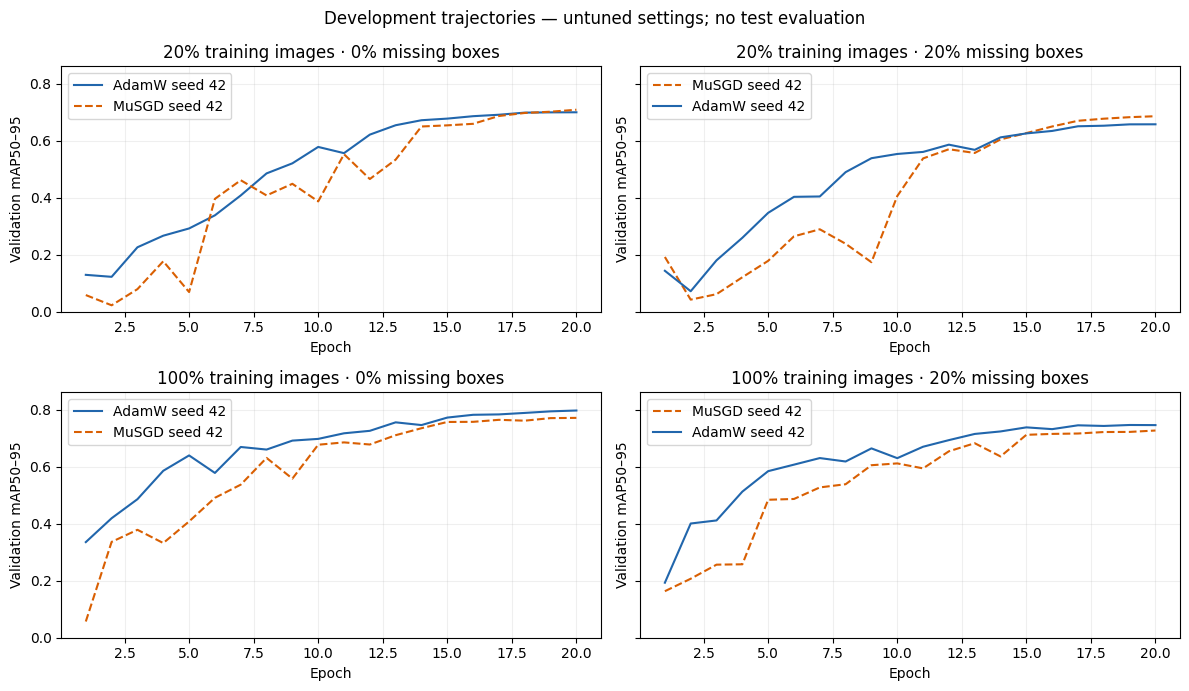

In [5]:
import matplotlib.pyplot as plt
conditions=sorted({(r['data_fraction'],r['noise_probability']) for r in completed})
cols=min(2,len(conditions)); height=3.5*math.ceil(len(conditions)/cols)
fig,axes=plt.subplots(math.ceil(len(conditions)/cols),cols,figsize=(6*cols,height),squeeze=False,sharey=True)
colors={'AdamW':'#2166ac','MuSGD':'#d95f02','SGD':'#1b9e77'}
styles={'AdamW':'-','MuSGD':'--','SGD':':'}
for ax,(fraction,noise) in zip(axes.flat,conditions):
    for r in completed:
        if (r['data_fraction'],r['noise_probability'])!=(fraction,noise):continue
        h=DATA['histories'][r['run_id']]
        ax.plot([e['epoch'] for e in h],[e['metrics/mAP50-95(B)'] for e in h],color=colors[r['optimizer']],linestyle=styles[r['optimizer']],label=f"{r['optimizer']} seed {r['seed']}")
    ax.set(title=f'{fraction:.0%} training images · {noise:.0%} missing boxes',xlabel='Epoch',ylabel='Validation mAP50–95')
    ax.grid(alpha=0.2);ax.legend()
for ax in list(axes.flat)[len(conditions):]:ax.set_visible(False)
upper=max((max(line.get_ydata()) for ax in axes.flat for line in ax.lines),default=0)*1.08
for ax in axes.flat:ax.set_ylim(0,upper or 1)
fig.suptitle('Development trajectories — untuned settings; no test evaluation')
fig.tight_layout();plt.show()


## 6. Corruption denominators and actual optimizer settings

In [6]:
for v in DATA['variants']:
    display(Markdown(f"Variant `{v['variant_id']}`: **{v['train_images']}** images; **{v['removed_objects']}/{v['original_train_objects']}** objects removed (**{v['realized_noise_rate']:.2%}**); **{v['empty_train_labels']}** empty training label files."))
group_table=['| Optimizer | Group | Parameters | Initial LR | Muon enabled |','|---|---|---:|---:|---|']
seen=set()
for r in completed:
    if r['optimizer'] in seen:continue
    seen.add(r['optimizer'])
    for g in r['optimizer_details']['groups']:
        if not g['parameters']:continue
        group_table.append(f"| {r['optimizer']} | {g.get('param_group','')} | {g['parameters']} | {g.get('initial_lr',g['lr']):.5f} | {g.get('use_muon',False)} |")
display(Markdown('\n'.join(group_table)))


Variant `f84eccc634a21018`: **205** images; **0/385** objects removed (**0.00%**); **0** empty training label files.

Variant `d22c5550717a3422`: **205** images; **72/385** objects removed (**18.70%**); **27** empty training label files.

Variant `ed9f2ae527533132`: **1021** images; **0/1881** objects removed (**0.00%**); **0** empty training label files.

Variant `7f518bd55dc48a76`: **1021** images; **361/1881** objects removed (**19.19%**); **126** empty training label files.

| Optimizer | Group | Parameters | Initial LR | Muon enabled |
|---|---|---:|---:|---|
| AdamW | weight | 2515728 | 0.00100 | False |
| AdamW | bn | 9784 | 0.00100 | False |
| AdamW | bias | 9832 | 0.00100 | False |
| MuSGD | bn | 2336 | 0.03000 | False |
| MuSGD | bn | 7448 | 0.01000 | False |
| MuSGD | bias | 2360 | 0.03000 | False |
| MuSGD | bias | 7472 | 0.01000 | False |
| MuSGD | muon | 124384 | 0.03000 | True |
| MuSGD | muon | 2391344 | 0.01000 | True |

## Class-specific validation AP
Each value is the saved best checkpoint's validation AP for that class, on the 0–1 scale.

In [7]:
names=[DATA['class_names'][str(i)] for i in range(len(DATA['class_names']))]
class_table=['| Fraction | Missing boxes | Optimizer | Seed | '+' | '.join(names)+' |', '|---:|---:|---|---:|'+'---:|'*len(names)]
for r in completed:
    values=r['val_per_class_map50_95']
    assert len(values)==len(names) and all(0<=v<=1 for v in values)
    prefix=f"| {r['data_fraction']:.0%} | {r['noise_probability']:.0%} | {r['optimizer']} | {r['seed']} | "
    class_table.append(prefix+' | '.join(f'{v:.4f}' for v in values)+' |')
display(Markdown('\n'.join(class_table)))


| Fraction | Missing boxes | Optimizer | Seed | buffalo | elephant | rhino | zebra |
|---:|---:|---|---:|---:|---:|---:|---:|
| 20% | 0% | AdamW | 42 | 0.6912 | 0.6688 | 0.7155 | 0.7178 |
| 20% | 0% | MuSGD | 42 | 0.6634 | 0.6795 | 0.7868 | 0.6943 |
| 20% | 20% | MuSGD | 42 | 0.6695 | 0.6062 | 0.7630 | 0.6904 |
| 20% | 20% | AdamW | 42 | 0.6686 | 0.6069 | 0.7019 | 0.6588 |
| 100% | 0% | AdamW | 42 | 0.8077 | 0.7753 | 0.8327 | 0.7715 |
| 100% | 0% | MuSGD | 42 | 0.7952 | 0.7410 | 0.8142 | 0.7402 |
| 100% | 20% | MuSGD | 42 | 0.7320 | 0.6972 | 0.7657 | 0.7064 |
| 100% | 20% | AdamW | 42 | 0.7590 | 0.7227 | 0.8038 | 0.7067 |

## Training-loss diagnostics
Box and classification losses use separate panels/scales. Lower training loss alone does not establish generalization or explain an optimizer mechanism.

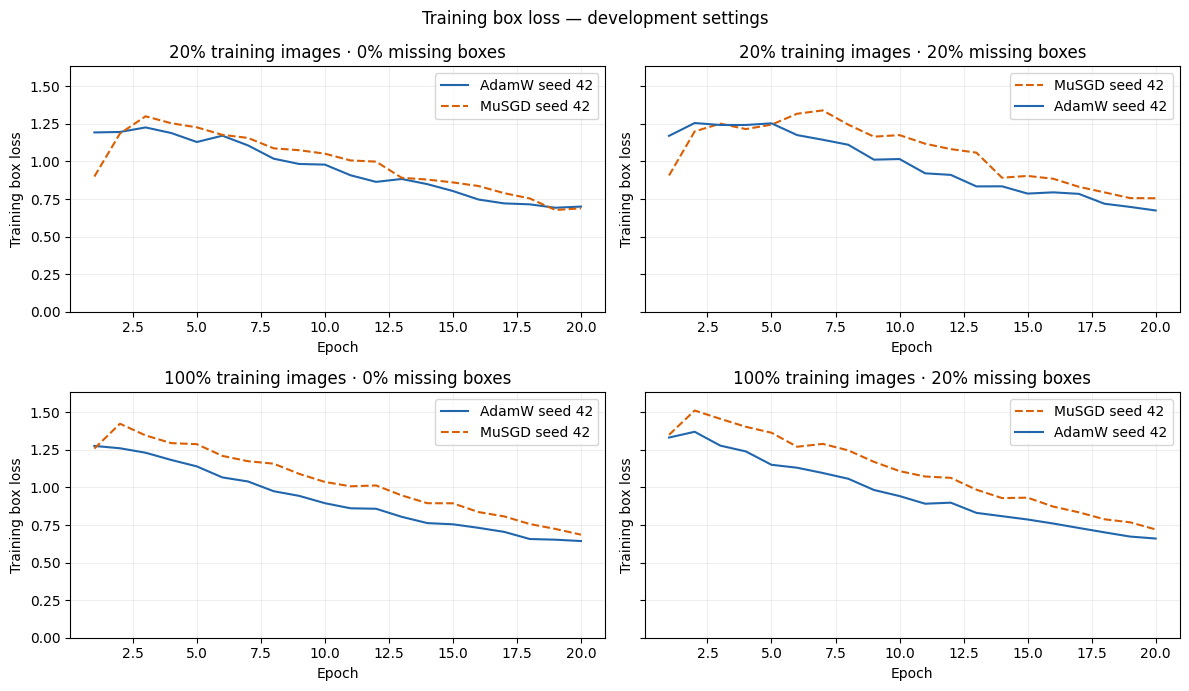

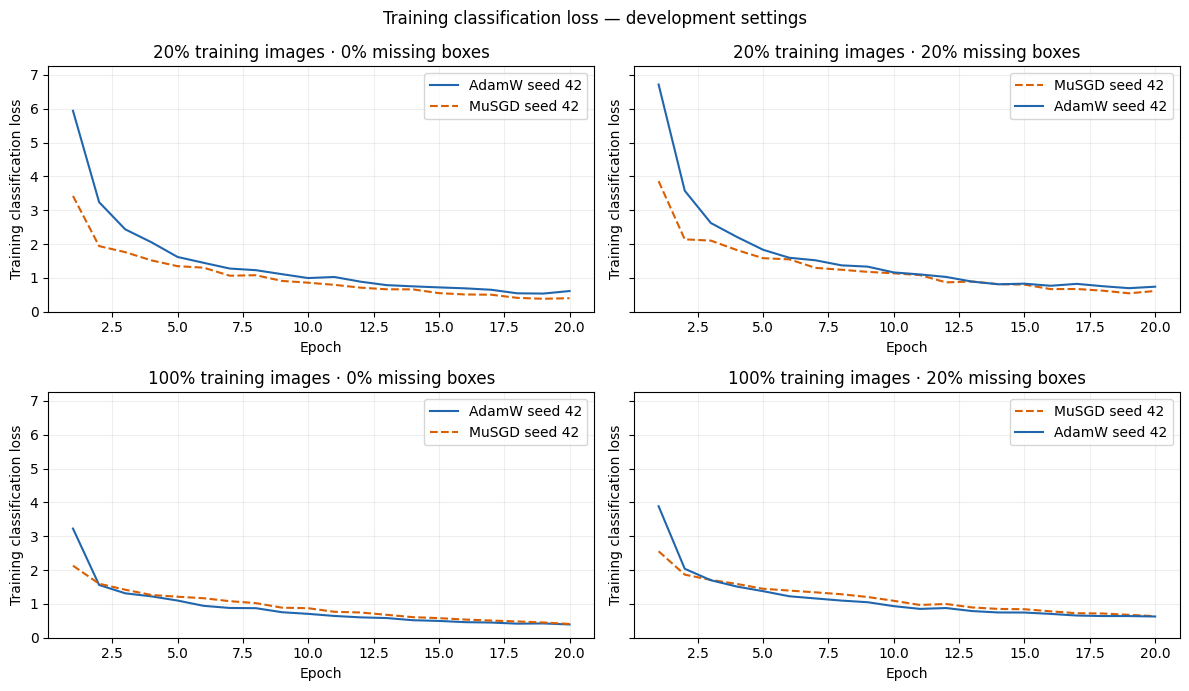

In [8]:
for field,ylabel in [('train/box_loss','Training box loss'),('train/cls_loss','Training classification loss')]:
    fig,axes=plt.subplots(math.ceil(len(conditions)/cols),cols,figsize=(6*cols,height),squeeze=False,sharey=True)
    for ax,(fraction,noise) in zip(axes.flat,conditions):
        for r in completed:
            if (r['data_fraction'],r['noise_probability'])!=(fraction,noise):continue
            h=DATA['histories'][r['run_id']]
            ax.plot([e['epoch'] for e in h],[e[field] for e in h],color=colors[r['optimizer']],linestyle=styles[r['optimizer']],label=f"{r['optimizer']} seed {r['seed']}")
        ax.set(title=f'{fraction:.0%} training images · {noise:.0%} missing boxes',xlabel='Epoch',ylabel=ylabel)
        ax.grid(alpha=0.2);ax.legend()
    for ax in list(axes.flat)[len(conditions):]:ax.set_visible(False)
    upper=max((max(line.get_ydata()) for ax in axes.flat for line in ax.lines),default=0)*1.08
    for ax in axes.flat:ax.set_ylim(0,upper or 1)
    fig.suptitle(ylabel+' — development settings')
    fig.tight_layout();plt.show()


## 7. What this evidence supports

Successful completion supports the experiment plumbing, deterministic variants and paired initialization checks. It does not establish a general optimizer advantage, a scarcity/noise interaction, a causal mechanism or significance. The implemented recipes differ in head LR multipliers and weight-decay behavior, and their LR defaults are untuned.

Before a final paper: add equal-budget tuning, SGD, repeated training/corruption seeds, an audited external dataset, defined timing boundaries and a frozen one-shot test protocol. Source annotation quality, image provenance, pretraining overlap and residual scene overlap remain limitations.

Source: measured Kaggle outputs identified by the embedded artifact hashes; methodological plans are in `research/PROTOCOL.md` and `research/RELATED_WORK.md`.